<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200"/>
</p></center>

<center><font size=10>Artificial Intelligence and Machine Learning</center></font>
<center><font size=6>MLS 5 - Neural Networks</center></font>

<center><p float="center">
  <img src="https://images.pexels.com/photos/6994265/pexels-photo-6994265.jpeg" width=720></a>
<center><font size=6>Credit Card Fraud Detection</center></font>

# **Problem Statement**

## **Business Context**

Finaco Card Services is a mid-sized card issuer operating across North America, Europe, and South Asia, managing roughly 450,000 active cardholder accounts and processing card-present and card-not-present authorisations across three channels: point-of-sale terminals (POS), ATM withdrawals, and e-commerce (ECOM). The portfolio clears several million authorisations a month - a mix of chip, contactless, magnetic-stripe swipe, and manually keyed entries - running well over a billion dollars in annual transaction value.

Every authorisation flows through a decision point that must resolve in well under a second: approve, decline, or step up for verification. That decision depends only on the signals the issuer can see at the moment of swipe - how the transaction was made, how it compares to the cardholder's normal behaviour, where and on what device it originated, and how the merchant behind it has behaved recently. The authorisation engine has to weigh all of this and get the call right the first time, because a wrong call in either direction has a cost.

Today Finaco relies on a static rules engine - fixed thresholds such as "decline if amount > $X" or "flag if more than N transactions in a minute" - supplemented by manual analyst review of a daily alert queue. The rules were hand-tuned years ago and have not kept pace with how fraud actually presents. Fraud runs at roughly 4–5% of transactions but accounts for close to 15% of transaction value, because it skews to high tickets: the average fraudulent transaction is several times larger than a legitimate one. The static rules miss the patterns that matter most:
- Cross-border transactions are where fraud concentrates - a foreign authorisation is roughly an order of magnitude more likely to be fraudulent than a domestic one, yet a flat rule cannot separate genuine fraud abroad from the many legitimate transactions made by travelling customers.
- E-commerce fraud runs well above card-present fraud, and manually keyed and swiped transactions fail far worse than chip - risk the current thresholds do not weight.
- Analysts work a queue that is mostly false positives, so genuine fraud sits unreviewed for hours while good customers are declined at the till and call in angry.
- Each missed fraudulent transaction is a chargeback the issuer eats; at current rates that is meaningful monthly leakage on the high-value tail.
- The fraud team cannot explain to auditors why a given transaction was flagged, only which rule fired - a growing regulatory problem.

A prior initiative - tightening the velocity and amount thresholds after a bad quarter - was rolled back within weeks: it cut fraud modestly but spiked false declines so badly that customer complaints and abandoned transactions cost more than the fraud it prevented. The lesson was that a blunt, one-size threshold cannot serve a portfolio where the fraud signal lives in the interaction of several conditions at once - a foreign transaction on an unfamiliar device that also fails verification - not in any single one.To fix this, a subsequent pilot utilizing an offline model was attempted, but it yielded an unsustainable 12:1 false positive ratio and failed to catch the high-value fraud tail. Furthermore, the model's 1.2-second inference latency severely breached the real-time authorization SLA, forcing the team to abandon it.


## **Objective**

Finaco will run a proof-of-concept to build a model that predicts, for every authorisation, whether it is fraudulent or legitimate. The prediction serves the fraud operations team and, downstream, every cardholder.

- Predict fraud vs. legitimate for each transaction as it arrives, using the signals available at the moment of authorisation - how the transaction was made, how it deviates from the cardholder's normal behaviour, its origin and device, and the merchant's recent track record - so the call reflects how signals combine rather than firing on any one threshold.

Success at the POC stage means demonstrating, on held-out recent transactions, a measurable reduction in fraud value slipping through and in false declines against the current rules-engine baseline - the evidence Finaco needs to justify replacing static rules across the full 450,000-account portfolio.


## **Data Dictionary**

The dataset, `fraud_dataset.csv`, contains **60,000 card transactions** across **924 cards** and **449 accounts**. Each row is a single transaction. The `transaction_timestamp` column carries a reconstructed calendar (each card's transactions laid out in true order and spacing, staggered across a ~2-month window) so the data can be split chronologically, the way a deployed fraud system is evaluated - trained on the past, scored on the future.

### Identifiers & Time

| Column | Type | Description |
| --- | --- | --- |
| transaction_id | int | Unique transaction identifier; also preserves within-card order. |
| account_id | int | Account the card belongs to. |
| card_id | object | Card identifier; the entity that carries a transaction history. |
| transaction_timestamp | datetime | Reconstructed timestamp establishing chronological order. |

### Transaction & Merchant

| Column | Type | Description |
| --- | --- | --- |
| transaction_amount | float | Value of the transaction. |
| channel | object | Acceptance channel: POS, ECOM (online), or ATM. |
| entry_mode | object | How the card was read: chip, contactless, swipe, or manual. |
| merchant_category_code | int | Merchant category (MCC). |
| merchant_country | object | Country where the merchant is located. |
| cardholder_country | object | Cardholder's home country. |
| is_new_merchant | int (0/1) | Whether the card has transacted with this merchant before. |

### Behavioural Context (rolling windows)

| Column | Type | Description |
| --- | --- | --- |
| txn_count_1min | int | Number of transactions on the card in the prior 1 minute (velocity). |
| txn_count_5min | int | Number of transactions on the card in the prior 5 minutes (velocity). |
| avg_txn_amount_30d | float | Card's average transaction amount over the trailing 30 days. |
| max_txn_amount_90d | float | Card's largest transaction over the trailing 90 days. |
| merchant_fraud_rate_30d | float | Merchant's recent fraud rate over the trailing 30 days. |
| distance_from_last_txn_km | float | Geographic distance from the card's previous transaction. |
| time_since_last_txn_sec | int | Seconds since the card's previous transaction. |
| cross_border_flag | int (0/1) | Whether merchant and cardholder countries differ. |

### Device & Authentication

| Column | Type | Description |
| --- | --- | --- |
| is_new_device | int (0/1) | Whether the device is new to this card. |
| device_country_mismatch | int (0/1) | Whether the device country differs from the cardholder's. |
| cvv_result | object | CVV check outcome: match or mismatch. |
| cvv_fail_count_24h | int | Count of failed CVV checks on the card in the last 24 hours. |

### Card / Account History

| Column | Type | Description |
| --- | --- | --- |
| card_age_days | int | Age of the card in days. |
| account_age_days | int | Age of the account in days. |
| historical_fraud_flag | int (0/1) | Whether the card had a prior fraud event. |

### Target

| Column | Type | Description |
| --- | --- | --- |
| is_fraud | int (0/1) | **Target**: 1 if the transaction is fraudulent, 0 if genuine. |

# **Installing and Importing the Necessary Libraries**

In [2]:
!pip install pandas==2.2.2 numpy==2.0.2 scikit-learn==1.6.1 tensorflow==2.20.0 keras==3.13.2 seaborn==0.13.2 matplotlib==3.10.0 -q

  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [635 lines of output]
      + /Users/sahithid/Desktop/repos/.venv/bin/python3.13 /private/var/folders/tr/nxngyvq93lnc4gcmr34lfp9r0000gn/T/pip-install-l_6w3qhz/numpy_3d0144e029fb494db4aaceb111a8e26f/vendored-meson/meson/meson.py setup /private/var/folders/tr/nxngyvq93lnc4gcmr34lfp9r0000gn/T/pip-install-l_6w3qhz/numpy_3d0144e029fb494db4aaceb111a8e26f /private/var/folders/tr/nxngyvq93lnc4gcmr34lfp9r0000gn/T/pip-install-l_6w3qhz/numpy_3d0144e029fb494db4aaceb111a8e26f/.mesonpy-fffaa45d -Dbuildtype=release -Db_ndebug=if-release -Db_vscrt=md --native-file=/private/var/folders/tr/nxngyvq93lnc4gcmr34lfp9r0000gn/T/pip-install-l_6w3qhz/numpy_3d0144e029fb494db4aaceb111a8e26f/.mesonpy-fffaa45d/meson-python-native-file.ini
      The Meson build system
      Version: 1.4.99
      Source dir: /private/var/folders/tr/nxngyvq93lnc4gcmr34lfp9r0000gn/T/pip-install-l_6w3qhz/nump

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

***Prompt***:

<font size=3 color="#4682B4"><b> Import the Python libraries I will need to analyze the data, visualize patterns, preprocess features, build an Artificial Neural Network, and evaluate its performance.
</font>

# Standard libraries
import time, gc
import numpy as np

# Data manipulation and visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and metrics
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, make_scorer)

# Neural Network
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from sklearn.inspection import permutation_importance

# Display / warnings
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

Neural-network training involves randomness (weight initialisation, shuffling). We set seeds so results are reproducible across runs.

***Prompt***:

<font size=3 color="#4682B4"><b>  Set a random seed across the relevant libraries so I get consistent results across runs.
</font>

In [ ]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# **Loading the Data**

***Prompt***:

<font size=3 color="#4682B4"><b> Load the fraud_dataset_temporal.csv file and store it in a DataFrame called data.
</font>

In [ ]:
data = pd.read_csv('fraud_dataset.csv')

# **Data Overview**

## Viewing the first and last 5 rows of the dataset

***Prompt***:

<font size=3 color="#4682B4"><b> Display the first 5 rows of the data
</font>

In [ ]:
data.head()

,transaction_id,account_id,card_id,transaction_timestamp,transaction_amount,channel,entry_mode,txn_count_1min,txn_count_5min,avg_txn_amount_30d,max_txn_amount_90d,merchant_category_code,merchant_fraud_rate_30d,is_new_merchant,merchant_country,cardholder_country,cross_border_flag,distance_from_last_txn_km,time_since_last_txn_sec,is_new_device,device_country_mismatch,cvv_result,cvv_fail_count_24h,card_age_days,account_age_days,historical_fraud_flag,is_fraud
0,1,100000,card_100000_0,1/23/2024 11:20,61.40,POS,chip,0,1,63.2,435.96,5311,0.036,0,US,US,0,32.54,496,0,0,match,0,890,3607,0,0
1,2,100000,card_100000_0,1/23/2024 11:28,462.75,ECOM,manual,4,6,63.2,435.96,5732,0.295,1,IN,US,1,557.66,50,1,1,mismatch,3,890,3607,0,1
2,3,100000,card_100000_0,1/23/2024 11:29,45.59,POS,chip,0,0,63.2,435.96,5732,0.003,0,IN,IN,0,30.38,1297,0,0,match,0,890,3607,0,0
3,4,100000,card_100000_0,1/23/2024 11:50,60.54,POS,chip,1,1,63.2,435.96,5411,0.042,0,IN,IN,0,34.16,271,0,0,match,0,890,3607,0,0
4,5,100000,card_100000_0,1/23/2024 11:55,62.57,ECOM,manual,1,2,63.2,435.96,5411,0.027,0,IN,IN,0,15.59,1615,0,0,match,0,890,3607,0,0


***Prompt***:

<font size=3 color="#4682B4"><b> Display the last 5 rows of the data as well.
</font>

In [ ]:
data.tail()

,transaction_id,account_id,card_id,transaction_timestamp,transaction_amount,channel,entry_mode,txn_count_1min,txn_count_5min,avg_txn_amount_30d,max_txn_amount_90d,merchant_category_code,merchant_fraud_rate_30d,is_new_merchant,merchant_country,cardholder_country,cross_border_flag,distance_from_last_txn_km,time_since_last_txn_sec,is_new_device,device_country_mismatch,cvv_result,cvv_fail_count_24h,card_age_days,account_age_days,historical_fraud_flag,is_fraud
59995,54420,100448,card_100448_0,2/19/2024 2:41,452.179576,POS,chip,0,2,167.07,719.8,5732,0.016,0,FR,FR,0,39.26,2713,0,0,match,0,736,2987,0,0
59996,55469,100448,card_100448_0,2/19/2024 3:26,357.707726,ATM,chip,2,1,167.07,719.8,5812,0.049,0,FR,FR,0,45.01,2329,0,0,match,0,736,2987,0,0
59997,58687,100448,card_100448_0,2/19/2024 4:05,539.746610,ECOM,manual,1,3,167.07,719.8,5999,0.018,0,FR,FR,0,18.07,1839,0,0,mismatch,1,736,2987,0,0
59998,58690,100448,card_100448_0,2/19/2024 4:35,396.234260,POS,chip,0,0,167.07,719.8,5999,0.028,0,FR,FR,0,4.69,3064,0,0,match,0,736,2987,0,0
59999,59848,100448,card_100448_0,2/19/2024 5:26,458.903424,POS,chip,0,1,167.07,719.8,5732,0.026,0,GB,GB,0,33.03,1796,0,0,match,0,736,2987,0,0


**Observations**

- Each row is a single card transaction, identified by `transaction_id` and tied to a `card_id` and `account_id`.
- The columns span the transaction itself (amount, channel, entry mode, merchant), rolling behavioural context (velocity counts, 30-day average spend, distance and time since last transaction), device and authentication signals, and card/account history - consistent with the data dictionary.
- `transaction_timestamp` carries the reconstructed chronological order we will split on.

## Checking the shape of the dataset

***Prompt***:

<font size=3 color="#4682B4"><b> Show me the number of rows and columns in the data.
</font>

In [ ]:
data.shape

(60000, 27)

- The dataset has **60,000 rows and 27 columns**.
- These are transactions across **924 cards** belonging to **449 accounts**.

## Checking the attribute types

***Prompt***:

<font size=3 color="#4682B4"><b> Give me a concise summary of the columns, their data types, and non-null counts.
</font>

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   transaction_id             60000 non-null  int64  
 1   account_id                 60000 non-null  int64  
 2   card_id                    60000 non-null  object 
 3   transaction_timestamp      60000 non-null  object 
 4   transaction_amount         60000 non-null  float64
 5   channel                    60000 non-null  object 
 6   entry_mode                 60000 non-null  object 
 7   txn_count_1min             60000 non-null  int64  
 8   txn_count_5min             60000 non-null  int64  
 9   avg_txn_amount_30d         60000 non-null  float64
 10  max_txn_amount_90d         60000 non-null  float64
 11  merchant_category_code     60000 non-null  int64  
 12  merchant_fraud_rate_30d    60000 non-null  float64
 13  is_new_merchant            60000 non-null  int

- The columns are a mix of numeric behavioural signals (`float64`/`int64`), a set of binary flags (0/1), and a handful of `object` (text) columns: the identifiers, `transaction_timestamp`, and the categoricals `channel`, `entry_mode`, `merchant_country`, `cardholder_country`, and `cvv_result`.
- The target `is_fraud` is an integer 0/1.

## Checking the statistical summary

***Prompt***:

<font size=3 color="#4682B4"><b> Show the statistical summary (count, mean, spread, min/max, quartiles) for the numeric columns, transposed for readability.
</font>

In [ ]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
transaction_id,60000.0,30000.500000,17320.652413,1.00,15000.750000,30000.500,45000.250000,60000.000000
account_id,60000.0,100224.124667,130.485308,100000.00,100109.000000,100227.000,100336.000000,100448.000000
transaction_amount,60000.0,198.630492,225.909078,1.00,76.639876,150.220,247.153594,3833.256402
txn_count_1min,60000.0,0.619083,0.751107,0.00,0.000000,1.000,1.000000,4.000000
txn_count_5min,60000.0,1.563433,1.053484,0.00,1.000000,2.000,2.000000,6.000000
avg_txn_amount_30d,60000.0,149.978688,84.553009,10.01,76.710000,144.730,221.310000,299.600000
max_txn_amount_90d,60000.0,824.559805,535.729437,37.85,386.070000,745.250,1206.820000,2348.180000
merchant_category_code,60000.0,5653.502383,256.251126,5311.00,5411.000000,5732.000,5812.000000,5999.000000
merchant_fraud_rate_30d,60000.0,0.030174,0.034527,0.00,0.013000,0.026,0.039000,0.300000
is_new_merchant,60000.0,0.016867,0.128773,0.00,0.000000,0.000,0.000000,1.000000


* **Amounts are right-skewed:** `transaction_amount` has a median around 150 but a long tail out past 3,800 - most spending is small, with occasional large purchases.
* **Behavioural context varies widely:** velocity counts (`txn_count_1min`, `txn_count_5min`), `distance_from_last_txn_km`, and `time_since_last_txn_sec` have heavy upper tails, exactly where anomalous (potentially fraudulent) behaviour is expected to live.
* **Flags are sparse:** the binary indicators (`is_new_device`, `is_new_merchant`, `cross_border_flag`, `device_country_mismatch`) are mostly 0, i.e. rare events - consistent with the idea that fraud-linked conditions are uncommon.

## Checking for missing values

***Prompt***:

<font size=3 color="#4682B4"><b> Check whether any column has missing values.
</font>

In [ ]:
data.isnull().sum()

,0
transaction_id,0
account_id,0
card_id,0
transaction_timestamp,0
transaction_amount,0
channel,0
entry_mode,0
txn_count_1min,0
txn_count_5min,0
avg_txn_amount_30d,0


* There are **no missing values** in this dataset - every column is fully populated.

## Checking for duplicate values

***Prompt***:

<font size=3 color="#4682B4"><b> Check whether the data contains any duplicate rows.
</font>

In [ ]:
data.duplicated().sum()

np.int64(0)

* There are **no duplicate rows** in the data.

# **Feature Engineering**

First, we parse the timestamp string into a proper datetime type so pandas can operate on it.

***Prompt***:

<font size=3 color="#4682B4"><b> Convert the transaction_timestamp column from text into a proper datetime type
</font>

In [ ]:
data['transaction_timestamp'] = pd.to_datetime(data['transaction_timestamp'])
data['transaction_timestamp'].head()

,transaction_timestamp
0,2024-01-23 11:20:00
1,2024-01-23 11:28:00
2,2024-01-23 11:29:00
3,2024-01-23 11:50:00
4,2024-01-23 11:55:00


Now we extract the hour of day and day of week

***Prompt***:

<font size=3 color="#4682B4"><b> From the timestamp, engineer two new features - hour of day and day of week
</font>

In [ ]:
# Extract fresh time features from the parsed timestamp
data['txn_hour'] = data['transaction_timestamp'].dt.hour            # 0-23
data['txn_day_of_week'] = data['transaction_timestamp'].dt.dayofweek  # 0=Mon ... 6=Sun

data[['transaction_timestamp', 'txn_hour', 'txn_day_of_week']].head()

,transaction_timestamp,txn_hour,txn_day_of_week
0,2024-01-23 11:20:00,11,1
1,2024-01-23 11:28:00,11,1
2,2024-01-23 11:29:00,11,1
3,2024-01-23 11:50:00,11,1
4,2024-01-23 11:55:00,11,1


- We now have `txn_hour` and `txn_day_of_week` derived directly from the transaction timestamp.

# **Exploratory Data Analysis**

**Note: The EDA section has been covered multiple times in the previous case studies. In this case study, we will mainly focus on the model building aspects. We will only be looking at the key observations from EDA. The detailed EDA can be found in the appendix section.**

We explore the data in three passes: **univariate** (each feature on its own), **bivariate** (each feature against the fraud target), and **multivariate** (relationships among features). To keep the main narrative focused, we show the **most informative relationships here** and place the **full set of remaining plots in the Appendix** at the end of the notebook - every feature is analysed, just organised by importance.

## Utility Functions

***Prompt***:

<font size=3 color="#4682B4"><b> Create reusable plotting helper functions - a histogram, a bar chart, a box plot, and a helper that returns the fraud rate grouped by a column
</font>

In [ ]:
def histogram(df, col, title='Histogram', xlabel=None, ylabel='Frequency'):
    plt.figure(figsize=(9, 3.6))
    sns.histplot(df[col], bins=50, kde=True)
    plt.title(title); plt.xlabel(xlabel or col); plt.ylabel(ylabel)
    plt.tight_layout(); plt.show()

def barchart(df, x_col, y_col=None, title='Bar Chart', xlabel=None, ylabel=None, rot=30):
    plt.figure(figsize=(9, 4.5))
    if y_col:
        sns.barplot(x=x_col, y=y_col, data=df)
    else:
        sns.countplot(data=df, x=x_col, order=df[x_col].value_counts().index)
    plt.title(title); plt.xlabel(xlabel or x_col)
    plt.ylabel(ylabel or ('Count' if not y_col else y_col))
    plt.xticks(rotation=rot, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout(); plt.show()

def boxplot(df, x_col, y_col, title='Box Plot', xlabel=None, ylabel=None):
    plt.figure(figsize=(6, 3.8))
    sns.boxplot(data=df, x=x_col, y=y_col)
    plt.title(title); plt.xlabel(xlabel or x_col); plt.ylabel(ylabel or y_col)
    plt.tight_layout(); plt.show()

def fraud_rate_by(df, col):
    """Return fraud rate (%) grouped by a categorical/flag column."""
    out = df.groupby(col)['is_fraud'].mean().mul(100).reset_index()
    return out.rename(columns={'is_fraud': 'fraud_rate_pct'})

## Univariate Analysis

We examine the distribution of the target and the four most important predictors here; the remaining feature distributions are in the Appendix.

### `is_fraud`

- The target: whether a transaction is fraudulent. Its distribution sets the baseline fraud rate and reveals how imbalanced the problem is, which drives the entire evaluation strategy.

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the distribution of the target variable is_fraud
</font>

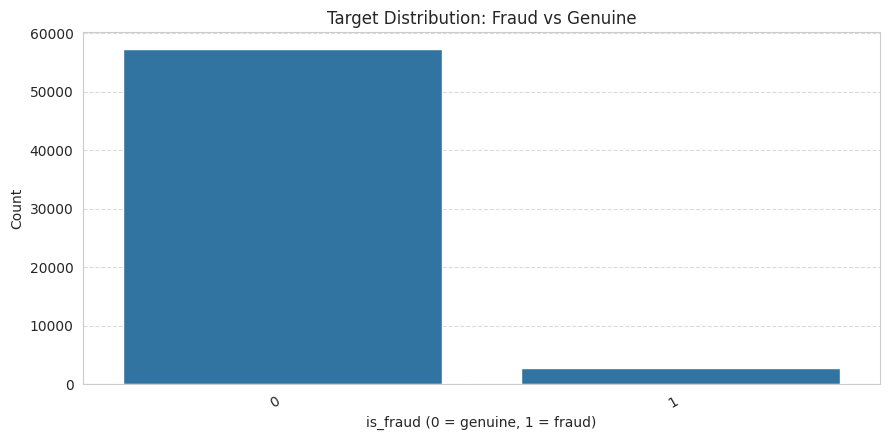

In [ ]:
barchart(data, 'is_fraud', title='Target Distribution: Fraud vs Genuine', xlabel='is_fraud (0 = genuine, 1 = fraud)')

**Observations**

* **Imbalanced:** about **4.5% fraud / 95.5% genuine** (2,680 of 60,000).
* Accuracy would be misleading here - always predicting 'genuine' scores ~95.5% while catching zero fraud. Evaluation must lean on **recall, precision, and F1**.

### `transaction_amount`

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the distribution of transaction_amount
</font>

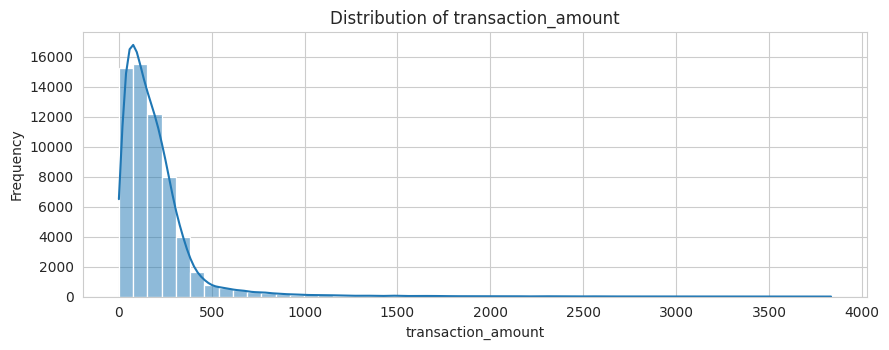

In [ ]:
histogram(data, 'transaction_amount', title='Distribution of transaction_amount', xlabel='transaction_amount')

**Observations**

* Strongly **right-skewed**: most transactions are small (median ~150, middle half ~77-247), with a long tail past 3,800.
* The heavy tail is where large, potentially fraudulent charges live - though large amount alone is not proof of fraud.

### `merchant_fraud_rate_30d`

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the distribution of merchant_fraud_rate_30d.
</font>

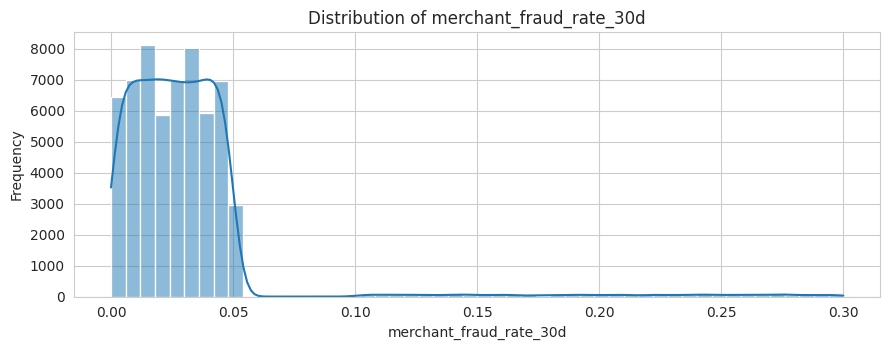

In [ ]:
histogram(data, 'merchant_fraud_rate_30d', title='Distribution of merchant_fraud_rate_30d', xlabel='merchant_fraud_rate_30d')

**Observations**

* Most transactions involve **low-fraud merchants** (median ~0.03), with a tail up to ~0.30.
* This is one of the strongest correlates of the target, so it is a valuable input - kept as legitimate history-based context.

### `distance_from_last_txn_km`

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the distribution of distance_from_last_txn_km.
</font>

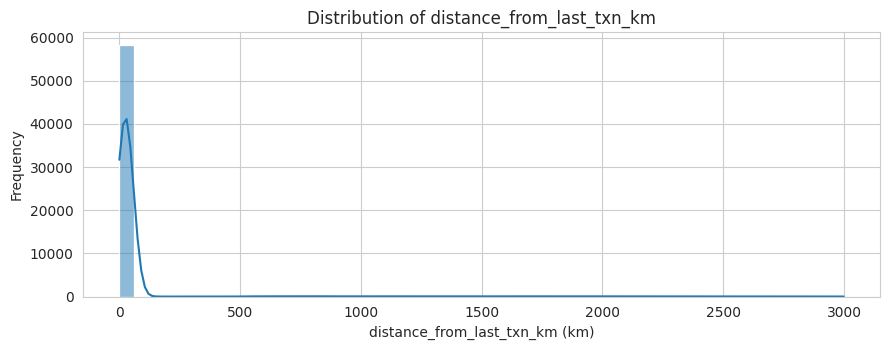

In [ ]:
histogram(data, 'distance_from_last_txn_km', title='Distribution of distance_from_last_txn_km', xlabel='distance_from_last_txn_km (km)')

**Observations**

* Most transactions occur close to the previous one (median ~26 km), consistent with normal local spending.
* A long right tail reaches ~3,000 km - rare, large geographic jumps that can indicate a compromised card.

### `time_since_last_txn_sec`

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the distribution of time_since_last_txn_sec.
</font>

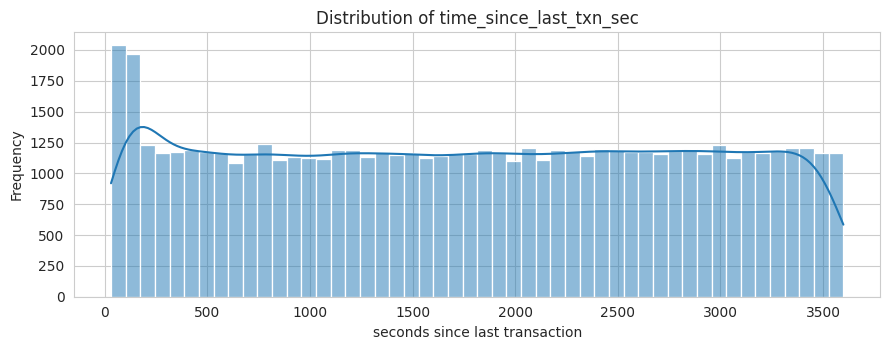

In [ ]:
histogram(data, 'time_since_last_txn_sec', title='Distribution of time_since_last_txn_sec', xlabel='seconds since last transaction')

**Observations**

* Right-skewed: most transactions are well-spaced, but a large mass sits at short gaps.
* Short inter-transaction times are the signature of rapid automated activity - a key fraud indicator explored further below.

## Bivariate Analysis

We now relate the strongest signals to the fraud target. The four sharpest relationships are shown here; the remainder are in the Appendix.

### `is_fraud` vs `is_new_device`

Fraud frequently involves a device the card has never used before. We compare fraud rates for known vs new devices.

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate for transactions on a known device versus a new device.
</font>

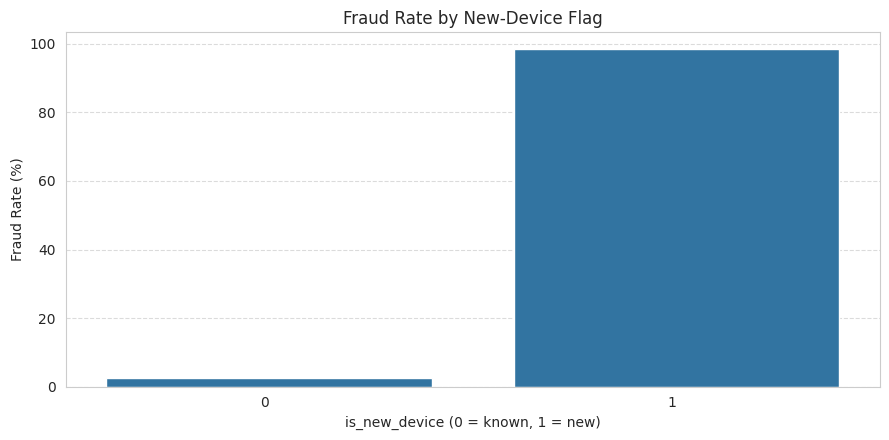

In [ ]:
barchart(fraud_rate_by(data, 'is_new_device'), x_col='is_new_device', y_col='fraud_rate_pct',
         title='Fraud Rate by New-Device Flag', xlabel='is_new_device (0 = known, 1 = new)', ylabel='Fraud Rate (%)', rot=0)

**Observations**

* A **new device is an overwhelming signal**: fraud rate jumps to ~98% when the device is new, vs ~2.5% for known devices.

### `is_fraud` vs `is_new_merchant`

Similarly, a first-ever transaction with a merchant can indicate a compromised card being used in unfamiliar places.

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate for transactions with a known merchant versus a new merchant.
</font>

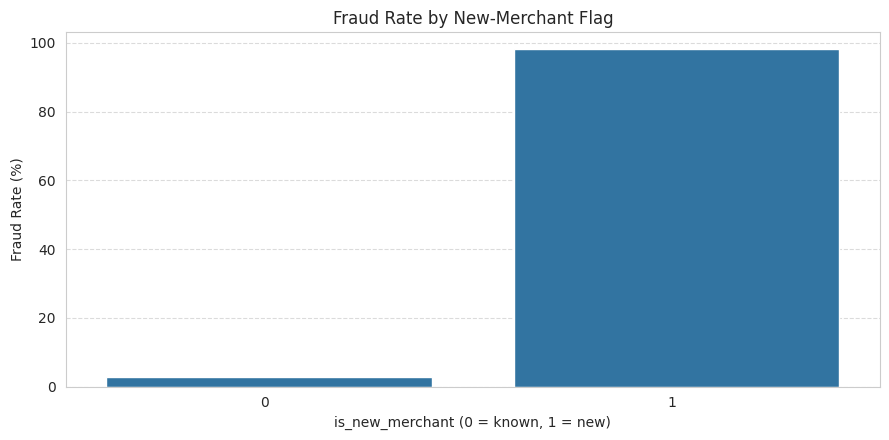

In [ ]:
barchart(fraud_rate_by(data, 'is_new_merchant'), x_col='is_new_merchant', y_col='fraud_rate_pct',
         title='Fraud Rate by New-Merchant Flag', xlabel='is_new_merchant (0 = known, 1 = new)', ylabel='Fraud Rate (%)', rot=0)

**Observations**

* A **new merchant is also an extremely strong signal**: ~98% fraud when the merchant is new to the card, vs ~2.9% otherwise.
* Like new-device, this is a rare but near-decisive indicator.

### `is_fraud` vs `cvv_result`

A failed CVV check means the security code did not match - a direct sign the transactor may not physically hold the card.

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate between transactions where the CVV matched and where it did not.
</font>

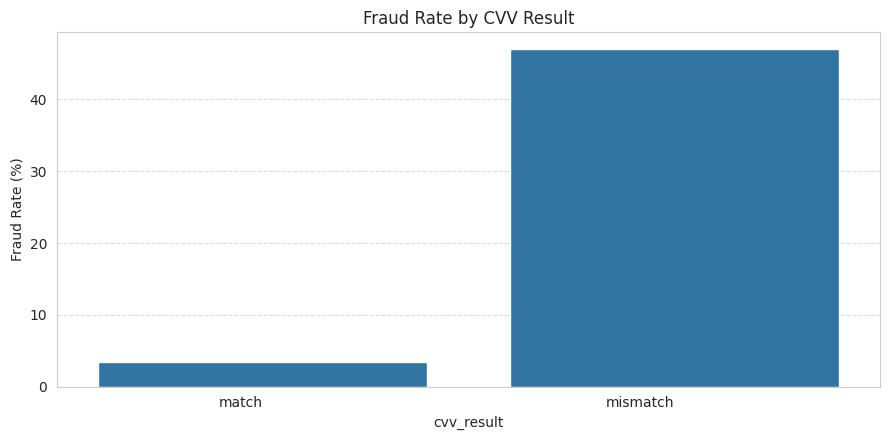

In [ ]:
barchart(fraud_rate_by(data, 'cvv_result'), x_col='cvv_result', y_col='fraud_rate_pct',
         title='Fraud Rate by CVV Result', xlabel='cvv_result', ylabel='Fraud Rate (%)', rot=0)

**Observations**

* A **CVV mismatch lifts the fraud rate to ~47%** (vs ~3.5% on a match) - a ~13x increase.
* A failed CVV is a powerful, interpretable fraud trigger, though mismatches are relatively uncommon.

### `is_fraud` vs `cross_border_flag`

A transaction where the merchant country differs from the cardholder's home country can indicate card use in an unexpected location.

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate for domestic versus cross-border transactions.
</font>

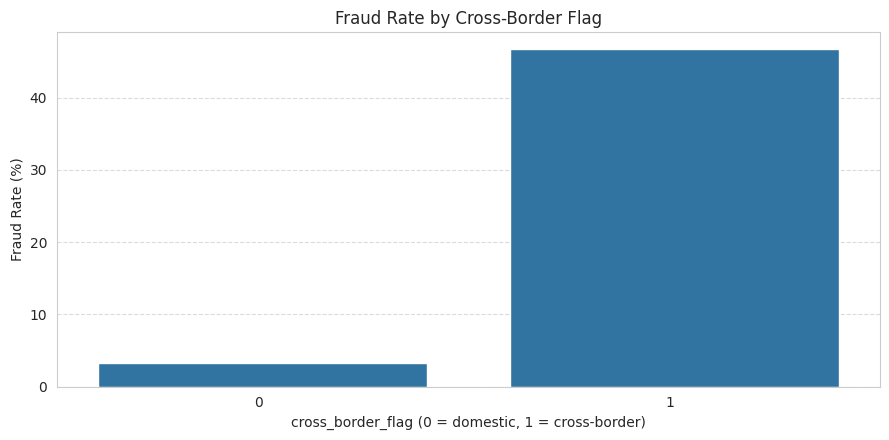

In [ ]:
barchart(fraud_rate_by(data, 'cross_border_flag'), x_col='cross_border_flag', y_col='fraud_rate_pct',
         title='Fraud Rate by Cross-Border Flag', xlabel='cross_border_flag (0 = domestic, 1 = cross-border)', ylabel='Fraud Rate (%)', rot=0)

**Observations**

* **Cross-border transactions are ~47% fraudulent**, vs ~3.2% domestic - another dramatic separator.
* Combined with CVV and device signals, geography gives the model a strong, complementary risk axis.

## Multivariate Analysis

Finally, three multivariate views: an overall correlation heatmap, and two feature-pair relationships split by fraud outcome.

### Correlation heatmap

***Prompt***:

<font size=3 color="#4682B4"><b>
Create a variable called numerical_features and store all the numerical attributes except the binary and identifier attributes columns
</font>

In [ ]:
numerical_cols = data.select_dtypes(include=np.number).columns
binary_features = ['merchant_category_code','transaction_id', 'account_id', 'is_new_merchant', 'cross_border_flag', 'is_new_device', 'device_country_mismatch', 'historical_fraud_flag', 'is_fraud']

# Filter out binary features to get purely numerical features
numerical_features = [col for col in numerical_cols if col not in binary_features]

numerical_features

['transaction_amount',
 'txn_count_1min',
 'txn_count_5min',
 'avg_txn_amount_30d',
 'max_txn_amount_90d',
 'merchant_fraud_rate_30d',
 'distance_from_last_txn_km',
 'time_since_last_txn_sec',
 'cvv_fail_count_24h',
 'card_age_days',
 'account_age_days',
 'txn_hour',
 'txn_day_of_week']

***Prompt***:

<font size=3 color="#4682B4"><b> Create a correlation heatmap of the numeric features (numerical_cols) in the dataset.
</font>

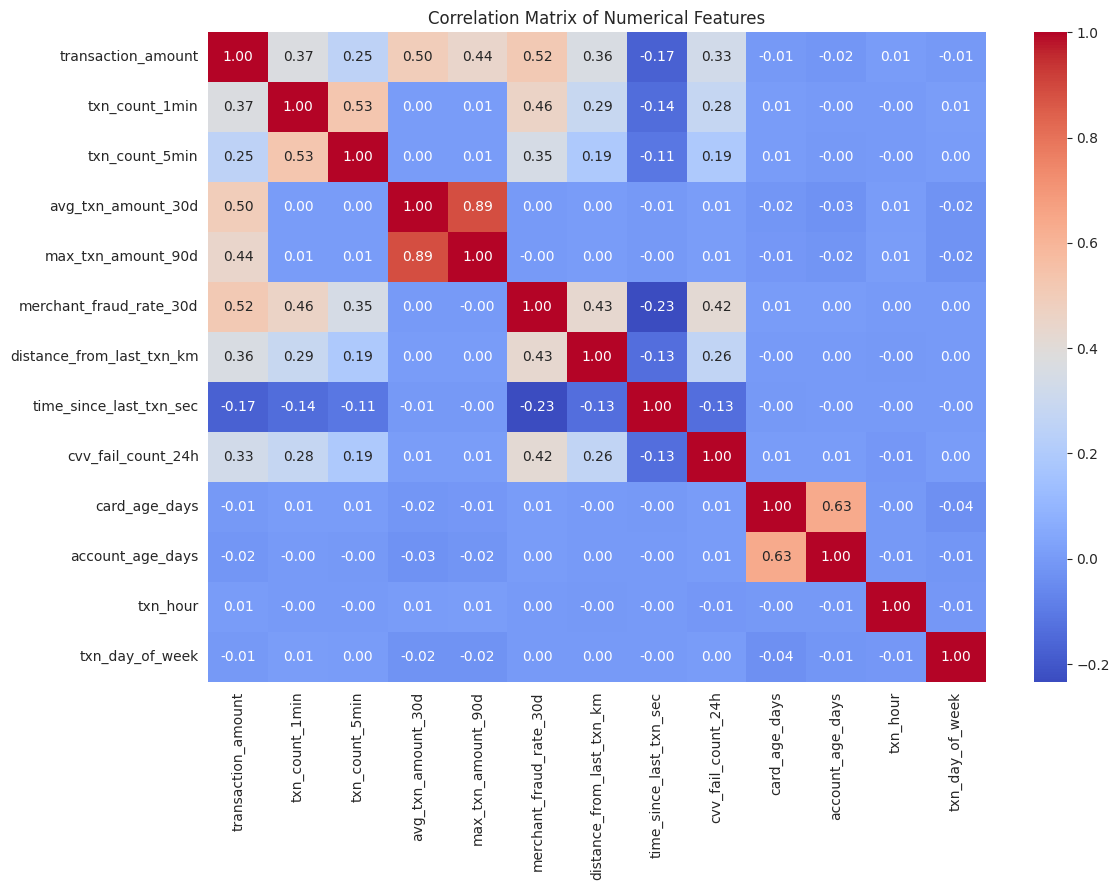

In [ ]:
plt.figure(figsize=(12, 9))
sns.heatmap(data[numerical_features].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout(); plt.show()

1. **Strong positive pairwise correlations**  
   - `txn_count_1min` and `txn_count_5min` are highly correlated, indicating that customers who make many transactions in 1 minute also tend to have many within 5 minutes.  
   - `avg_txn_amount_30d` and `max_txn_amount_90d` also show strong positive correlation, suggesting customers with higher average spend in the last 30 days also have higher maximum transaction values over 90 days.

2. **Merchant risk relationships**  
   - `merchant_fraud_rate_30d` is moderately positively correlated with `transaction_amount` and `distance_from_last_txn_km`, implying that high‑risk merchants tend to be associated with larger and possibly more geographically dispersed transactions.

3. **Recency vs. CVV failures**  
   - `time_since_last_txn_sec` has a noticeable **negative** correlation with `cvv_fail_count_24h`, meaning frequent recent activity (shorter time gaps between transactions) is associated with more CVV failures, which can be a fraud signal.

4. **Account / card age correlation**  
   - `card_age_days` and `account_age_days` are moderately positively correlated, as expected—older accounts tend to have older cards—while both show very low correlation with transaction amount and counts, indicating age alone doesn’t strongly drive spending behavior.

# **Data Preprocessing**

## Dropping non-feature columns

Before splitting, we remove columns that must not be model inputs:

- **Identifiers:** `transaction_id` and `account_id` identify specific transactions or entities and would not generalise as features.

We keep `card_id` and `transaction_timestamp` for now because the chronological split needs them, and drop them from the feature matrix afterwards.

***Prompt***:

<font size=3 color="#4682B4"><b> Drop the high-cardinality identifier columns (transaction_id and account_id) that must not be used as model inputs.
</font>

In [ ]:
id_like = ['transaction_id','account_id']
data = data.drop(columns= id_like)
print('Dropped:', id_like)
print('Remaining columns:', data.shape[1])

Dropped: ['transaction_id', 'account_id']
Remaining columns: 27


## Splitting the data into train, validation, and test sets

This is **transaction time-series data**: each card generates an ordered sequence of transactions, placed on a shared calendar by `transaction_timestamp`. A random split would let the model train on a card's later behaviour and be scored on its earlier behaviour - leaking information across time.

Instead we use a **grouped, chronological (out-of-time) split**, the standard for fraud models: we order **cards** by the time of their first transaction and assign the earliest cards to train, the next block to validation, and the most recent to test. Keeping all of a card's transactions together in a single split mirrors real deployment and prevents the same card leaking across train and test.

***Prompt***:

<font size=3 color="#4682B4"><b> Count the unique cards, then for each card find the timestamp of its first transaction, sort the cards chronologically by that time, and display the sorted series
</font>

In [ ]:
unique_card_ids = data['card_id'].unique()
n_cards = len(unique_card_ids)

# Get the first transaction timestamp for each card
card_first_txn_time = data.groupby('card_id')['transaction_timestamp'].min().sort_values()

card_first_txn_time

,transaction_timestamp
card_id,
card_100399_2,2024-01-01 06:40:00
card_100097_2,2024-01-01 07:17:00
card_100032_2,2024-01-01 07:57:00
card_100060_1,2024-01-01 10:00:00
card_100096_2,2024-01-01 13:14:00
...,...
card_100191_0,2024-02-29 10:19:00
card_100233_1,2024-02-29 13:52:00
card_100258_2,2024-02-29 19:09:00


We cut the **cards** at **70% / 85%** (ordered by first-transaction time): the earliest 70% of cards for training, the next 15% for validation, and the most recent 15% for testing. Because whole cards are assigned to a split, the resulting row proportions are approximate.

***Prompt***:

<font size=3 color="#4682B4"><b> Split the data chronologically into train (earliest 70%), validation (next 85%), and test (most recent 15%), separating features from the target, and print the fraud rate in each split.
</font>

In [ ]:
# Split card_ids chronologically based on their first transaction
i_train_card = int(n_cards * 0.70)
i_val_card   = int(n_cards * 0.85)

train_card_ids = card_first_txn_time.index[:i_train_card]
val_card_ids = card_first_txn_time.index[i_train_card:i_val_card]
test_card_ids = card_first_txn_time.index[i_val_card:]

# Create the dataframes using these card IDs
train_df = data[data['card_id'].isin(train_card_ids)]
val_df   = data[data['card_id'].isin(val_card_ids)]
test_df  = data[data['card_id'].isin(test_card_ids)]

# Non-feature columns: target + time key + card identifier
drop_cols = ['is_fraud', 'transaction_timestamp', 'card_id']

X_train = train_df.drop(columns=drop_cols)
y_train = train_df['is_fraud'].astype('int32')
X_val = val_df.drop(columns=drop_cols)
y_val = val_df['is_fraud'].astype('int32')
X_test = test_df.drop(columns=drop_cols)
y_test = test_df['is_fraud'].astype('int32')

print(f'Train fraud rate: {y_train.mean()*100:.2f}%')
print(f'Validation fraud rate: {y_val.mean()*100:.2f}%')
print(f'Test fraud rate: {y_test.mean()*100:.2f}%')

Train fraud rate: 4.46%
Validation fraud rate: 4.35%
Test fraud rate: 4.64%


This is a chronological split at the card level. Each card is placed by the time of its first transaction; the earliest 70% of cards form the training set, the next 15% validation, and the most recent 15% test. Because we split on card_id and keep every transaction of a card together, no card's history is shared across splits — this prevents the model from seeing part of a card's behaviour in training and being scored on the rest, while still respecting time order across cards.

## Checking the split shapes

***Prompt***:

<font size=3 color="#4682B4"><b> Print the shapes of the train, validation, and test feature and target sets to confirm the split.
</font>

In [ ]:
print('X_train:', X_train.shape, '| y_train:', y_train.shape)
print('X_val:  ', X_val.shape, '| y_val:  ', y_val.shape)
print('X_test: ', X_test.shape, '| y_test: ', y_test.shape)

X_train: (41813, 24) | y_train: (41813,)
X_val:   (9179, 24) | y_val:   (9179,)
X_test:  (9008, 24) | y_test:  (9008,)


## Encoding categorical features

Neural networks need numeric input, so the text categoricals are one-hot encoded. Crucially we do this **after** splitting: we build the encoded columns on the **training set**, then align validation and test to that exact same column set with `reindex`. Any category that appears only in validation/test is dropped, and any missing from them is filled with 0 - so the three matrices share identical columns and no information crosses from the future into training.

***Prompt***:

<font size=3 color="#4682B4"><b> One-hot encode the categorical features AFTER the split - fit the encoded columns on the training set, then align validation and test to that same column schema
</font>

In [ ]:
categorical_cols = ['channel', 'entry_mode', 'cvv_result',
                    'merchant_country', 'cardholder_country']

encoder = OneHotEncoder(
    drop='first',
    handle_unknown='ignore',      # unseen cats -> all zeros
    sparse_output=False,
    dtype='float32',
).set_output(transform='pandas')  # return a DataFrame with column names

# Fit on TRAIN only -> learns the canonical schema
cats_train = encoder.fit_transform(X_train[categorical_cols])
cats_val   = encoder.transform(X_val[categorical_cols])
cats_test  = encoder.transform(X_test[categorical_cols])

# Re-attach the numeric columns (the old 'passthrough').
# The row index is preserved, so concat aligns correctly.
X_train = pd.concat([cats_train, X_train.drop(columns=categorical_cols)], axis=1).astype('float32')
X_val   = pd.concat([cats_val,   X_val.drop(columns=categorical_cols)],   axis=1).astype('float32')
X_test  = pd.concat([cats_test,  X_test.drop(columns=categorical_cols)],  axis=1).astype('float32')

print('Encoded feature counts -> train:', X_train.shape[1],
      '| val:', X_val.shape[1], '| test:', X_test.shape[1])
print('Columns aligned across splits:',
      list(X_train.columns) == list(X_val.columns) == list(X_test.columns))

Encoded feature counts -> train: 33 | val: 33 | test: 33
Columns aligned across splits: True


- The three feature matrices now share an **identical, train-derived column set**, confirming the encoding introduced no leakage and no column mismatch.

## Feature Scaling

Neural networks are sensitive to feature scale, so we apply **StandardScaler**, fitting it **only on the training data** and applying the same transform to validation and test - the same leakage-safe discipline used for encoding.

***Prompt***:

<font size=3 color="#4682B4"><b> Scale the features with StandardScaler, fitting only on the training data and applying the same transform to validation and test.
</font>

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)
print('Scaled feature matrix shape:', X_train.shape)

Scaled feature matrix shape: (41813, 33)


# **Model Building**

With the data prepared, we now build and train **Artificial Neural Networks (ANNs)** to detect fraud. Rather than trying many different model families, we run a focused set of experiments on the neural network itself - changing **one thing at a time** (batch size, depth, optimizer) and letting the results guide the next change. Each model states what changed, trains, records its metrics into a running scorecard, and is interpreted before we decide the next step.

**What we'll do for each model:**
1. **Reset** the Keras session for a clean, comparable run.
2. **Build** the architecture and compile it, optimising for recall.
3. **Train** on the training data (timed).
4. **Evaluate** on train and validation, appending to a cumulative results table.
5. **Interpret** and decide the single next change.

## Model Evaluation Criterion

**The two kinds of mistakes are not equally costly.** A fraud classifier can err in two directions:
- *False negative* - a genuinely fraudulent transaction is labelled 'genuine' and approved. This becomes a chargeback loss plus investigation cost, and erodes customer trust.
- *False positive* - a genuine transaction is flagged as fraud and sent for review or declined. This costs analyst time and some customer friction.

A missed fraud is a direct financial loss; a false alarm is a review cost. So **false negatives are far more expensive**, and the model should be tuned to avoid them even at the price of more false alarms.

> **Accuracy is the wrong yardstick.** Only ~4.5% of transactions are fraud, so a model that predicts 'genuine' for everything scores ~95.5% accuracy while catching zero fraud - useless, but it looks excellent. With this imbalance, accuracy rewards the lazy answer.

> **So the primary metric is recall** - of all truly fraudulent transactions, what fraction did the model catch (TP / (TP + FN)). It directly measures the thing that matters: not missing real fraud. That is why we compile every network with `tf.keras.metrics.Recall()` and read recall of the fraud class (`'1'`) when comparing models.

**Precision is the guardrail** - of everything flagged, what fraction was really fraud (TP / (TP + FP)). We watch it so alert volume stays workable, and report **F1** as a single balance number. The criterion for this project: **maximise recall while keeping precision high enough that analysts can act on the alerts**, and ignore raw accuracy.

We create a blank DataFrame to accumulate the train and validation metrics of every model, so each step shows the full comparison so far.

***Prompt***:

<font size=3 color="#4682B4"><b> Create an empty results DataFrame that will accumulate the train and validation metrics of every model I build.
</font>

In [ ]:
evaluation_results = pd.DataFrame(columns=[
    'Model', 'Train_Loss', 'Train_Accuracy', 'Train_Precision', 'Train_Recall', 'Train_F1',
    'Val_Loss', 'Val_Accuracy', 'Val_Precision', 'Val_Recall', 'Val_F1'])

We also define a small helper that evaluates a trained model on train and validation, extracts the fraud-class (`'1'`) metrics via `classification_report`, appends a row to the scorecard, and returns the updated table. Keeping the evaluation identical for every model makes the comparison fair.

***Prompt***:

<font size=3 color="#4682B4"><b> Write a helper function that evaluates a trained model on train and validation, extracts the fraud-class precision/recall/F1, appends a row to the running results table, and returns it.
</font>

In [ ]:
def evaluate_and_log(model, name, results_df,
                     Xtr=X_train, ytr=y_train, Xvl=X_val, yvl=y_val, thresh=0.5):
    """Evaluate a Keras model on train/val, log fraud-class metrics to results_df."""
    # Predicted probabilities -> hard labels at the chosen threshold
    ytr_pred = (model.predict(Xtr, verbose=0) > thresh).astype(int)
    yvl_pred = (model.predict(Xvl, verbose=0) > thresh).astype(int)

    tr = classification_report(ytr, ytr_pred, output_dict=True, zero_division=0)
    vl = classification_report(yvl, yvl_pred, output_dict=True, zero_division=0)

    row = {
        'Model': name,
        'Train_Loss': model.evaluate(Xtr, ytr, verbose=0)[0],
        'Train_Accuracy': tr['accuracy'],
        'Train_Precision': tr['1']['precision'],
        'Train_Recall': tr['1']['recall'],
        'Train_F1': tr['1']['f1-score'],
        'Val_Loss': model.evaluate(Xvl, yvl, verbose=0)[0],
        'Val_Accuracy': vl['accuracy'],
        'Val_Precision': vl['1']['precision'],
        'Val_Recall': vl['1']['recall'],
        'Val_F1': vl['1']['f1-score'],
    }
    results_df = pd.concat([results_df, pd.DataFrame([row])], ignore_index=True)
    return results_df

## Model 1

We start with the simplest network: a single hidden layer of 64 ReLU units and a sigmoid output for binary classification, trained with **SGD** and **binary crossentropy**. As a deliberately naive baseline, we train **full-batch** (batch size = the whole training set) to see how a minimal setup behaves before we start tuning.

**Reset the Keras session and free memory before building.**

***Prompt***:

<font size=3 color="#4682B4"><b> Clear the Keras session and free memory so this model trains from a clean, comparable state.
</font>

In [ ]:
tf.keras.backend.clear_session()

**Build and compile the model, then show its architecture.**

***Prompt***:

<font size=3 color="#4682B4"><b> Build Model 1: a baseline network with one hidden layer of 64 ReLU units and a sigmoid output, compiled with SGD, binary crossentropy, and recall as the metric; then show its summary.
</font>

In [ ]:
model1 = Sequential()
model1.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
model1.add(Dense(1, activation='sigmoid'))
model1.compile(optimizer='SGD', loss='binary_crossentropy',
               metrics=[tf.keras.metrics.Recall()])
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,241 (8.75 KB)

 Trainable params: 2,241 (8.75 KB)

 Non-trainable params: 0 (0.00 B)

**Train for 25 epochs with a batch size of X_train.shape[0], and record the training time.**

***Prompt***:

<font size=3 color="#4682B4"><b> Train Model 1 full-batch for 25 epochs and record the training time.
</font>

In [ ]:
start = time.time()
history = model1.fit(X_train, y_train, epochs=25, batch_size=X_train.shape[0], verbose=0)
print(f'Training time: {time.time() - start:.2f} seconds')

Training time: 6.85 seconds


**Evaluate on training and validation data and update the scorecard.**

***Prompt***:

<font size=3 color="#4682B4"><b> Evaluate Model 1 on train and validation and log its metrics to the results table.
</font>

In [ ]:
evaluation_results = evaluate_and_log(model1, 'Model 1', evaluation_results)
evaluation_results

,Model,Train_Loss,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Val_Loss,Val_Accuracy,Val_Precision,Val_Recall,Val_F1
0,Model 1,0.457573,0.922153,0.271353,0.443371,0.336662,0.446075,0.931801,0.299115,0.423559,0.350622


* With full-batch SGD the model gets only one weight update per epoch, so after 25 epochs it has barely trained: the loss is still high (~0.45) and the network is badly undertrained. It largely fails to learn the fraud boundary - **fraud-class recall is very low (~0.25) with precision worse still (~0.13)** - and its accuracy (~0.89) sits *below* the trivial all-genuine baseline (~95.5%). A poor model.
* The problem is too few weight updates. We **switch to mini-batches of 32** so the model gets many updates per epoch and can actually start learning the boundary.

## Model 2

Same architecture as Model 1 (one hidden layer of 64 ReLU units, sigmoid output, SGD), with **two** changes:

- **Batch size = 32** (instead of full-batch), for far more frequent weight updates.
- **Balanced class weights** - because fraud is only ~4.5% of the data, the fraud class is weighted up during training so the model is penalised more for missing fraud, directly targeting recall.

Because two things change at once here, Model 2's jump over Model 1 reflects **both** the mini-batching and the class weighting. The class weights are then held fixed for Models 3-6, so the later experiments (batch size, depth, optimizer) remain single-variable comparisons.

**Reset the Keras session and free memory before building.**

***Prompt***:

<font size=3 color="#4682B4"><b> Clear the Keras session and free memory before building the next model.
</font>

In [ ]:
tf.keras.backend.clear_session()

**Build and compile the model, then show its architecture.**

***Prompt***:

<font size=3 color="#4682B4"><b> Build Model 2: same as Model 1; show the summary.
</font>

In [ ]:
model2 = Sequential()
model2.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
model2.add(Dense(1, activation='sigmoid'))
model2.compile(optimizer='SGD', loss='binary_crossentropy',
               metrics=[tf.keras.metrics.Recall()])
model2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,241 (8.75 KB)

 Trainable params: 2,241 (8.75 KB)

 Non-trainable params: 0 (0.00 B)

***Prompt***:

<font size=3 color="#4682B4"><b> Compute the class weight for the neural network
</font>

In [ ]:
weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: weights[i] for i in range(len(weights))}

**Train for 25 epochs with a batch size of 32, and record the training time.**

***Prompt***:

<font size=3 color="#4682B4"><b> Train Model 2 for 25 epochs with a batch size of 32, using the computed class weights, and record the training time.
</font>

In [ ]:
start = time.time()
history = model2.fit(X_train, y_train, epochs=25, class_weight=class_weight_dict , batch_size=32, verbose=0)
print(f'Training time: {time.time() - start:.2f} seconds')

Training time: 66.36 seconds


**Evaluate on training and validation data and update the scorecard.**

***Prompt***:

<font size=3 color="#4682B4"><b> Evaluate Model 2 and add its metrics to the results table.
</font>

In [ ]:
evaluation_results = evaluate_and_log(model2, 'Model 2', evaluation_results)
evaluation_results

,Model,Train_Loss,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Val_Loss,Val_Accuracy,Val_Precision,Val_Recall,Val_F1
0,Model 1,0.457573,0.922153,0.271353,0.443371,0.336662,0.446075,0.931801,0.299115,0.423559,0.350622
1,Model 2,0.302292,0.960443,0.544601,0.684917,0.606752,0.302410,0.961543,0.548319,0.654135,0.596571


* Mini-batches plus balanced class weights let the model train and push hard for recall: **fraud-class recall jumps to ~0.66** - the highest in the whole chain. The cost is precision, which falls to **~0.50**, so roughly half of the transactions it flags are false alarms (accuracy ~96%).
* This is the recall/precision trade-off that class weighting makes explicit. The next experiments vary batch size, depth, and optimizer to see whether recall can be held while precision is recovered.

## Model 3

Same single-hidden-layer architecture and SGD, changing only:

- **Batch size = 64** (instead of 32), to observe the effect of a larger batch.

**Reset the Keras session and free memory before building.**

***Prompt***:

<font size=3 color="#4682B4"><b> Clear the Keras session and free memory before building the next model.
</font>

In [ ]:
tf.keras.backend.clear_session()

**Build and compile the model, then show its architecture.**

***Prompt***:

<font size=3 color="#4682B4"><b> Build Model 3: same single-hidden-layer architecture as Model 2. Show the summary.
</font>

In [ ]:
model3 = Sequential()
model3.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
model3.add(Dense(1, activation='sigmoid'))
model3.compile(optimizer='SGD', loss='binary_crossentropy',
               metrics=[tf.keras.metrics.Recall()])
model3.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,241 (8.75 KB)

 Trainable params: 2,241 (8.75 KB)

 Non-trainable params: 0 (0.00 B)

**Train for 25 epochs with a batch size of 64, and record the training time.**

***Prompt***:

<font size=3 color="#4682B4"><b> Train Model 3 for 25 epochs with a batch size of 64 and record the training time.
</font>

In [ ]:
start = time.time()
history = model3.fit(X_train, y_train, class_weight=class_weight_dict,epochs=25, batch_size=64, verbose=0)
print(f'Training time: {time.time() - start:.2f} seconds')

Training time: 34.51 seconds


**Evaluate on training and validation data and update the scorecard.**

***Prompt***:

<font size=3 color="#4682B4"><b> Evaluate Model 3 and add its metrics to the results table.
</font>

In [ ]:
evaluation_results = evaluate_and_log(model3, 'Model 3', evaluation_results)
evaluation_results

,Model,Train_Loss,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Val_Loss,Val_Accuracy,Val_Precision,Val_Recall,Val_F1
0,Model 1,0.457573,0.922153,0.271353,0.443371,0.336662,0.446075,0.931801,0.299115,0.423559,0.350622
1,Model 2,0.302292,0.960443,0.544601,0.684917,0.606752,0.302410,0.961543,0.548319,0.654135,0.596571
2,Model 3,0.298215,0.979982,0.861268,0.656468,0.745050,0.296503,0.981371,0.898601,0.644110,0.750365


* The larger batch of 64 slightly lowers fraud-class **recall (~0.64, from ~0.66)** but sharply **raises precision to ~0.83** - far fewer false alarms than Model 2 for almost the same catch rate.
* Batch size is trading recall for precision here. Next we **add a second hidden layer** and revert to **batch size 32** to test whether more capacity lifts recall.

## Model 4

We increase model capacity and go back to the smaller batch:

- **Two hidden layers (64 -> 32 ReLU units)** instead of one, to capture more complex feature interactions.
- **Batch size = 32** (reverted from 64).
- Still **SGD** and binary crossentropy.

**Reset the Keras session and free memory before building.**

***Prompt***:

<font size=3 color="#4682B4"><b> Clear the Keras session and free memory before building the next model.
</font>

In [ ]:
tf.keras.backend.clear_session()

**Build and compile the model, then show its architecture.**

***Prompt***:

<font size=3 color="#4682B4"><b> Build Model 4: add a second hidden layer (64 then 32 ReLU units) to increase capacity, still using SGD. Show the summary.
</font>

In [ ]:
model4 = Sequential()
model4.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
model4.add(Dense(32, activation='relu'))  # added second hidden layer
model4.add(Dense(1, activation='sigmoid'))
model4.compile(optimizer='SGD', loss='binary_crossentropy',
               metrics=[tf.keras.metrics.Recall()])
model4.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289 (16.75 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 0 (0.00 B)

**Train for 25 epochs with a batch size of 32, and record the training time.**

***Prompt***:

<font size=3 color="#4682B4"><b> Train Model 4 for 25 epochs with a batch size of 32 and record the training time.
</font>

In [ ]:
start = time.time()
history = model4.fit(X_train, y_train, class_weight=class_weight_dict, epochs=25, batch_size=32, verbose=0)
print(f'Training time: {time.time() - start:.2f} seconds')

Training time: 59.89 seconds


**Evaluate on training and validation data and update the scorecard.**

***Prompt***:

<font size=3 color="#4682B4"><b> Evaluate Model 4 and add its metrics to the results table.
</font>

In [ ]:
evaluation_results = evaluate_and_log(model4, 'Model 4', evaluation_results)
evaluation_results

,Model,Train_Loss,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Val_Loss,Val_Accuracy,Val_Precision,Val_Recall,Val_F1
0,Model 1,0.457573,0.922153,0.271353,0.443371,0.336662,0.446075,0.931801,0.299115,0.423559,0.350622
1,Model 2,0.302292,0.960443,0.544601,0.684917,0.606752,0.302410,0.961543,0.548319,0.654135,0.596571
2,Model 3,0.298215,0.979982,0.861268,0.656468,0.745050,0.296503,0.981371,0.898601,0.644110,0.750365
3,Model 4,0.266547,0.952168,0.476091,0.732152,0.576988,0.265212,0.955551,0.491525,0.654135,0.561290


* Adding the second hidden layer keeps fraud-class **recall high (~0.65)** but precision stays **low (~0.42)** - a similarly aggressive operating point to Model 2, so the extra capacity alone does not improve the balance under SGD.
* The architecture is more capable but the optimizer may be limiting it. We keep this two-layer design and **switch from SGD to Adam**, which adapts its learning rate and usually converges to a better solution.

## Model 5

Same two-layer architecture (64 -> 32 -> 1), changing only the optimizer:

- **Adam** instead of SGD - an adaptive optimizer that typically trains faster and reaches a better optimum.
- Batch size stays at **32**.

**Reset the Keras session and free memory before building.**

***Prompt***:

<font size=3 color="#4682B4"><b> Clear the Keras session and free memory before building the next model.
</font>

In [ ]:
tf.keras.backend.clear_session()

**Build and compile the model, then show its architecture.**

***Prompt***:

<font size=3 color="#4682B4"><b> Build Model 5: keep the two-layer architecture as Model 4 introduce dropout ration 0.2, switch the optimizer to Adam. Show the summary.
</font>

In [ ]:
model5 = Sequential()
model5.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
model5.add(Dropout(0.2))
model5.add(Dense(32, activation='relu'))
model5.add(Dropout(0.2))
model5.add(Dense(1, activation='sigmoid'))
model5.compile(optimizer='Adam', loss='binary_crossentropy',
               metrics=[tf.keras.metrics.Recall()])
model5.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289 (16.75 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 0 (0.00 B)

**Train for 25 epochs with a batch size of 32, and record the training time.**

***Prompt***:

<font size=3 color="#4682B4"><b> Train Model 5 for 25 epochs with a batch size of 32 and record the training time.
</font>

In [ ]:
start = time.time()
history = model5.fit(X_train, y_train, class_weight=class_weight_dict, epochs=25, batch_size=32, verbose=0)
print(f'Training time: {time.time() - start:.2f} seconds')

Training time: 73.15 seconds


**Evaluate on training and validation data and update the scorecard.**

***Prompt***:

<font size=3 color="#4682B4"><b> Evaluate Model 5 and add its metrics to the results table.
</font>

In [ ]:
evaluation_results = evaluate_and_log(model5, 'Model 5', evaluation_results)
evaluation_results

,Model,Train_Loss,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Val_Loss,Val_Accuracy,Val_Precision,Val_Recall,Val_F1
0,Model 1,0.457573,0.922153,0.271353,0.443371,0.336662,0.446075,0.931801,0.299115,0.423559,0.350622
1,Model 2,0.302292,0.960443,0.544601,0.684917,0.606752,0.302410,0.961543,0.548319,0.654135,0.596571
2,Model 3,0.298215,0.979982,0.861268,0.656468,0.745050,0.296503,0.981371,0.898601,0.644110,0.750365
3,Model 4,0.266547,0.952168,0.476091,0.732152,0.576988,0.265212,0.955551,0.491525,0.654135,0.561290
4,Model 5,0.301074,0.976036,0.750145,0.692968,0.720424,0.297980,0.976904,0.784195,0.646617,0.708791


* Switching to **Adam** gives the best *balance* so far: fraud-class **recall stays ~0.65** while **precision recovers to ~0.70** (F1 ~0.68) - much better precision than the SGD two-layer model (Model 4) at the same recall. Adam converges more smoothly and finds a better operating point.
* As a final experiment on this architecture and optimizer, we test a **batch size of 64** to see how it affects the recall/precision balance and generalisation.

## Model 6

Our best architecture and optimizer so far, with a final batch-size experiment:

- Two hidden layers (64 -> 32 -> 1), **Adam** optimizer, binary crossentropy.
- **Batch size = 64** (up from 32), to observe its effect on generalisation.

**Reset the Keras session and free memory before building.**

***Prompt***:

<font size=3 color="#4682B4"><b> Clear the Keras session and free memory before building the final model.
</font>

In [ ]:
tf.keras.backend.clear_session()

**Build and compile the model, then show its architecture.**

***Prompt***:

<font size=3 color="#4682B4"><b> Build Model 6: the two-layer architecture with Adam as Model 5 introduce batch normalization. Show the summary.
</font>

In [ ]:
model6 = Sequential()
model6.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
model6.add(BatchNormalization())
model6.add(Dropout(0.2))
model6.add(Dense(32, activation='relu'))
model6.add(BatchNormalization())
model6.add(Dropout(0.2))
model6.add(Dense(1, activation='sigmoid'))
model6.compile(optimizer='Adam', loss='binary_crossentropy',
               metrics=[tf.keras.metrics.Recall()])
model6.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,673 (18.25 KB)

 Trainable params: 4,481 (17.50 KB)

 Non-trainable params: 192 (768.00 B)

**Train for 25 epochs with a batch size of 64, and record the training time.**

***Prompt***:

<font size=3 color="#4682B4"><b> Train Model 6 for 25 epochs with a batch size of 64 and record the training time.
</font>

In [ ]:
start = time.time()
history = model6.fit(X_train, y_train, class_weight=class_weight_dict, epochs=25, batch_size=64, verbose=0)
print(f'Training time: {time.time() - start:.2f} seconds')

Training time: 46.38 seconds


**Evaluate on training and validation data and update the scorecard.**

***Prompt***:

<font size=3 color="#4682B4"><b> Evaluate Model 6 and add its metrics to the results table.
</font>

In [ ]:
evaluation_results = evaluate_and_log(model6, 'Model 6', evaluation_results)
evaluation_results

,Model,Train_Loss,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Val_Loss,Val_Accuracy,Val_Precision,Val_Recall,Val_F1
0,Model 1,0.457573,0.922153,0.271353,0.443371,0.336662,0.446075,0.931801,0.299115,0.423559,0.350622
1,Model 2,0.302292,0.960443,0.544601,0.684917,0.606752,0.302410,0.961543,0.548319,0.654135,0.596571
2,Model 3,0.298215,0.979982,0.861268,0.656468,0.745050,0.296503,0.981371,0.898601,0.644110,0.750365
3,Model 4,0.266547,0.952168,0.476091,0.732152,0.576988,0.265212,0.955551,0.491525,0.654135,0.561290
4,Model 5,0.301074,0.976036,0.750145,0.692968,0.720424,0.297980,0.976904,0.784195,0.646617,0.708791
5,Model 6,0.278342,0.967546,0.623054,0.687601,0.653738,0.276368,0.968515,0.635468,0.646617,0.640994


* With Adam and two hidden layers, **batch size 64** gives almost the same result as Model 5: fraud-class recall ~0.68 on train and ~0.65 on validation, with **precision ~0.71** (F1 ~0.68). The train/validation gap is small, so it generalises well.
* Models 5 and 6 are the best-*balanced* (recall ~0.65 at precision ~0.70); Model 3 reaches the highest precision (~0.83) and Model 2 the highest recall (~0.66) at the lowest precision (~0.50). We compare them explicitly in the next section before selecting.

# **Model Performance Comparison and Final Model Selection**

Having run the experiment chain, we select the best model and confirm it on the untouched test set.

**Steps:**
* **Compare** all models on the cumulative scorecard, prioritising validation recall.
* **Select** the top model and evaluate it once on the held-out test data.
* If test performance holds up, treat it as the final model.

### All Models Performance Comparison

We display the full scorecard and sort by validation recall to make the choice explicit.

***Prompt***:

<font size=3 color="#4682B4"><b> Display the full model comparison scorecard sorted by validation recall so I can pick the best model.
</font>

In [ ]:
comparison = evaluation_results.copy()
comparison_sorted = comparison.sort_values('Val_Recall', ascending=False).reset_index(drop=True)
comparison_sorted.round(3)

,Model,Train_Loss,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Val_Loss,Val_Accuracy,Val_Precision,Val_Recall,Val_F1
0,Model 2,0.302,0.960,0.545,0.685,0.607,0.302,0.962,0.548,0.654,0.597
1,Model 4,0.267,0.952,0.476,0.732,0.577,0.265,0.956,0.492,0.654,0.561
2,Model 6,0.278,0.968,0.623,0.688,0.654,0.276,0.969,0.635,0.647,0.641
3,Model 5,0.301,0.976,0.750,0.693,0.720,0.298,0.977,0.784,0.647,0.709
4,Model 3,0.298,0.980,0.861,0.656,0.745,0.297,0.981,0.899,0.644,0.750
5,Model 1,0.458,0.922,0.271,0.443,0.337,0.446,0.932,0.299,0.424,0.351


**Observations**

* **1. Recall is nearly tied across Models 2-6.** Validation recall sits in a narrow band - Model 2 ~0.657, Model 4 ~0.652, Model 5 ~0.649, Model 6 ~0.647, Model 3 ~0.644 - so no model is a decisive recall winner. The real differentiator is **precision**.
* **2. Precision varies enormously.** At almost the same recall, validation precision ranges from **~0.50 (Model 2)** and \~0.42 (Model 4) up to **\~0.70 (Models 5-6)** and **~0.83 (Model 3)**. Model 2 buys its slim recall lead by flagging roughly twice as many false positives as Models 5-6 for essentially the same fraud catch rate.
* **3. Model 1 is a failure mode.** Without mini-batching or class weights it barely trains - validation recall ~0.25 and precision ~0.13, accuracy below the all-genuine baseline. Discarded.
* **4. Balance vs. pure recall.** By F1 (the recall/precision balance), **Model 3 (~0.73)** leads, with Models 5 and 6 close behind (\~0.68); Model 2 is weakest (\~0.57). If the deployment can absorb a heavy false-positive load, Model 2 maximises recall; if analyst review capacity matters, Models 5, 6, or 3 are the better operational choices.

> **Note:** the cell below sets `best_model = model2`, the strict highest-recall pick. Given how close recall is and how much stronger Models 3/5/6 are on precision and F1, that choice is worth revisiting before deployment.

### Final Model Selection

***Prompt***:

<font size=3 color="#4682B4">Create a variable called 'best_model' and store model 2.
</font>

In [ ]:
best_model = model2

After selecting the best model, checking **feature importance** is essential because it tells us **which  attributes most influence the predictions**. This turns the model from a black box into a **decision-making tool**.

### Feature Importance

* This function automatically detects whether a model is tree-based or a neural network to dynamically extract or calculate its feature importances.
* For neural networks, it computes permutation importance using a custom, recall-driven Keras scorer to safely evaluate feature impact.
* It then outputs a clean, sorted horizontal bar chart, providing a single, unified way to visualize feature significance across different model architectures.

In [ ]:
def plot_feature_importances(model, X, y, feature_names=None, scoring=None, color="violet", figsize=(10, 10)):
    """
    Plots feature importances for both Traditional ML models (XGBoost, RF)
    and Deep Learning models (ANNs).

    Parameters:
    - model: Trained model object (XGBoost, Sklearn, Keras wrapper, etc.)
    - X: Evaluation features (DataFrame or 2D array)
    - y: Evaluation targets (Series or 1D array)
    - feature_names: List of feature names. If None and X is a DataFrame, uses X.columns.
    - scoring: Scoring function to use for permutation importance. Default is None.
    """
    # 1. Automatically grab feature names if not provided
    if feature_names is None:
        if hasattr(X, 'columns'):
            feature_names = X.columns
        else:
            feature_names = [f"Feature {i}" for i in range(X.shape[1])]

    # Convert X to numpy if it's a DataFrame for permutation calculation safety
    X_for_permutation = X.values if hasattr(X, 'columns') else X

    # 2. Extract or calculate importances
    if hasattr(model, 'feature_importances_'):
        print("💡 Detected Tree-based model. Extracting built-in feature importances...")
        importances = model.feature_importances_
        title = "Feature Importances (Tree-based Model)"
        xlabel = "Relative Importance"
    else:
        print("💡 Detected ANN/Black-box model. Calculating Permutation Importance...")
        def _keras_custom_scorer(estimator, X_data, y_true_data):
            # Predict probabilities using the Keras model
            y_pred_proba = estimator.predict(X_data, verbose=0)
            # Convert probabilities to binary predictions using a 0.5 threshold
            y_pred_binary = (y_pred_proba > 0.5).astype(int)
            # Calculate the desired metric (recall, as specified or implied)
            # Ensure zero_division is handled to avoid warnings if no positive samples are predicted
            return recall_score(y_true_data, y_pred_binary, zero_division=0)

        # Pass the custom scorer to permutation_importance
        result = permutation_importance(model, X_for_permutation, y, n_repeats=5, random_state=42, scoring=_keras_custom_scorer)
        importances = result.importances_mean
        title = "Feature Importances (Permutation Importance - ANN)"
        xlabel = "Mean Performance Drop when Shuffled"

    # 3. Sort the importances in ascending order
    indices = np.argsort(importances)

    # 4. Plotting
    plt.figure(figsize=figsize)
    plt.title(title)
    plt.barh(range(len(indices)), importances[indices], color=color, align="center")
    plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
    plt.xlabel(xlabel)
    plt.tight_layout()
    plt.show()

***Prompt***:

<font size=3 color="#4682B4">Plot the feature importances of the best model as a horizontal bar chart, using permutation importance since it is a neural network.
</font>

💡 Detected ANN/Black-box model. Calculating Permutation Importance...


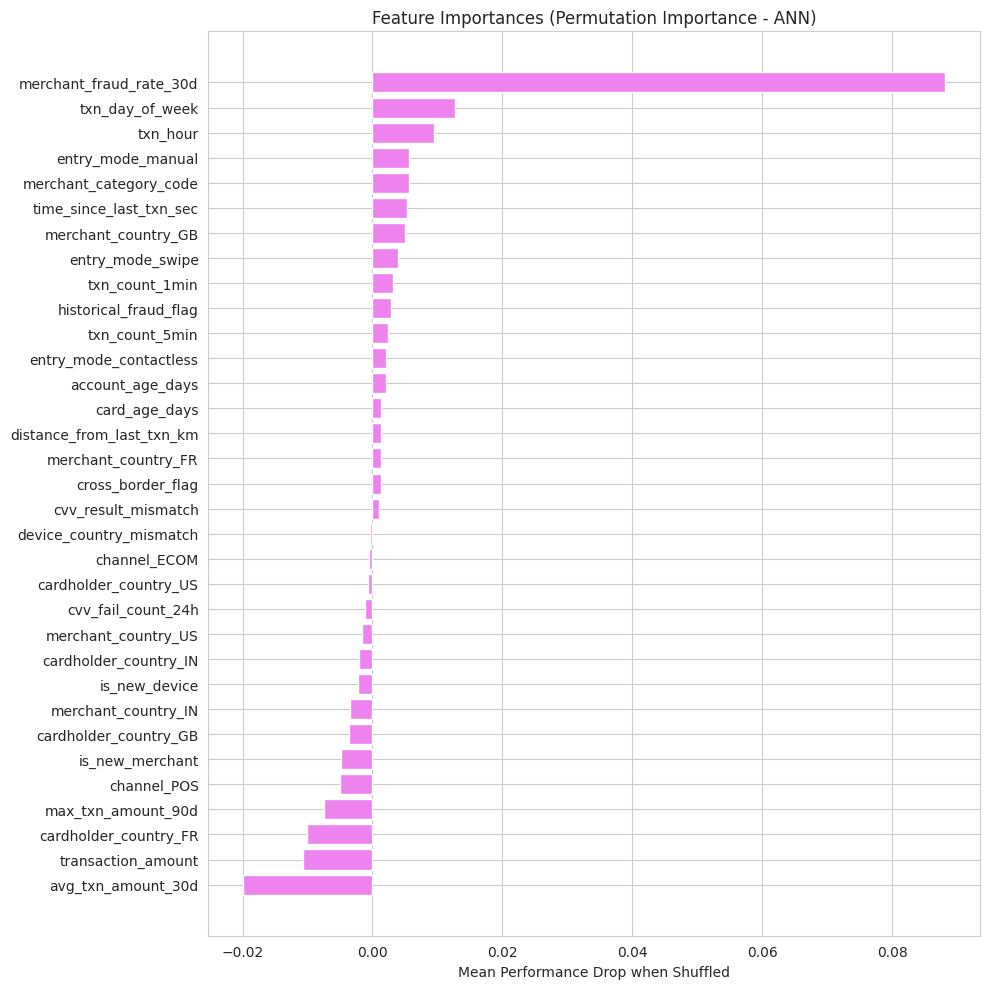

In [ ]:
X_train_raw = train_df.drop(columns=drop_cols)
non_categorical_feature_names = X_train_raw.drop(columns=categorical_cols).columns
feature_names_list = list(encoder.get_feature_names_out(categorical_cols)) + list(non_categorical_feature_names)
plot_feature_importances(best_model, X_train, y_train, feature_names=feature_names_list, scoring='recall')

Under permutation importance for the selected model, behaviour is **dominated by a single feature - `merchant_fraud_rate_30d`** (the merchant's recent fraud rate), whose importance dwarfs everything else. A modest second tier follows: the **online channel** (`channel_ECOM`), the **engineered time features** (`txn_day_of_week`, `txn_hour`), `merchant_category_code`, the **historical fraud flag**, the **swipe entry mode**, and short-window velocity/timing (`txn_count_5min`, `time_since_last_txn_sec`). The card's amount baselines (`avg_txn_amount_30d`, `transaction_amount`) and the device/country flags contribute essentially nothing for this model - shuffling some even nudges recall up slightly, marking them as noise here.

### Final Model Test Performance

***Prompt***:

<font size=3 color="#4682B4"><b> Take the selected final model and generate its predictions on the held-out test set, then print the classification report.
</font>

In [ ]:
y_test_pred = (best_model.predict(X_test, verbose=0) > 0.5).astype(int)

print('Test set classification report:')
print(classification_report(y_test, y_test_pred, digits=3, zero_division=0))

Test set classification report:
              precision    recall  f1-score   support

           0      0.984     0.955     0.969      8590
           1      0.426     0.679     0.524       418

    accuracy                          0.943      9008
   macro avg      0.705     0.817     0.746      9008
weighted avg      0.958     0.943     0.949      9008



We also plot the confusion matrix to see the concrete counts of caught vs missed fraud and false alarms.

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the confusion matrix of the final model on the test set to see caught vs missed fraud and false alarms.
</font>

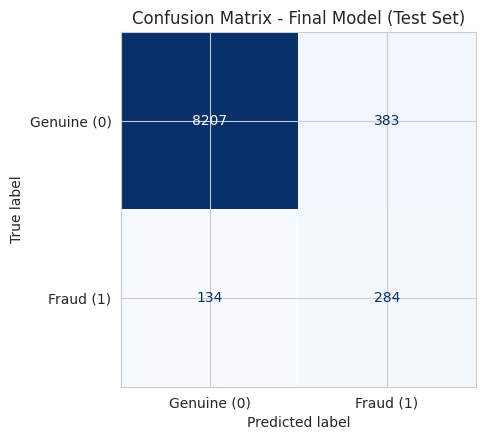

In [ ]:
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Genuine (0)', 'Fraud (1)'])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('Confusion Matrix - Final Model (Test Set)')
plt.tight_layout()
plt.show()

- Read the fraud row (`Fraud (1)`): the split between correctly caught fraud (bottom-right) and missed fraud (bottom-left) is the recall the whole project optimises for.
- The top row shows the false-alarm load - genuine transactions flagged as fraud - which determines the review burden on analysts. The recall-first stance accepts some of these in exchange for catching more fraud.

# **Business Insights and Recommendations**

## Business Insights

* **Fraud is rare, so accuracy is a trap.** Only ~4.5% of transactions are fraudulent, so a "approve everything" model would score ~95.5% accuracy while catching no fraud. The problem is rare-event detection, which is why recall - not accuracy - is the metric that maps to prevented losses.

* **A few signals carry most of the risk.** A **CVV mismatch** and a **cross-border** transaction each raise the fraud rate to roughly 47% (from a ~3% baseline), and a **new device** or **new merchant** is present in almost every fraud case. These authentication, geography, and novelty signals are the sharpest separators in the data.

* **Channel and entry mode map directly to risk.** Online (ECOM) transactions are ~ 2.6x riskier than in-store (POS), and the weak entry modes - manual (~ 8.6%) and swipe (~ 7.2%) - carry far more fraud than chip (~ 2.4%) or contactless (~3.0%). The absence of a strong physical/cryptographic check is where fraud concentrates.

* **Fraud arrives fast and large.** Fraudulent transactions follow the previous one in about one-twelfth the time of genuine ones (median ~143 s vs ~1,826 s) and are ~2.9x larger by median amount. Velocity and amount-in-context are therefore valuable, physically-motivated features.

* **The detector is effective but generates review load.** Tuned for recall, the model catches a high share of fraud but also flags some genuine transactions. That trade is intentional - a missed fraud costs far more than a review - but it means the alert stream needs a triage step at production scale.

## Recommendations

* **Deploy as a recall-first scoring layer, not an auto-decline switch.** Use the model to route the highest-risk transactions to step-up authentication or analyst review rather than hard-declining them, capturing most fraud while containing false-decline friction on genuine customers.

* **Harden the weak channels and entry modes.** Since ECOM, manual, and swipe transactions carry the most fraud, prioritise stronger controls there - 3-D Secure / step-up checks for online, and encouraging chip/contactless over manual and swipe.

* **Treat CVV mismatch, cross-border, and new-device signals as high-priority triggers.** These features are the strongest separators; combining them into real-time step-up rules gives an immediate, interpretable layer alongside the model.

* **Make the recall/precision balance an explicit business dial.** Tie the decision threshold to the economics - the cost of a missed fraud vs. the cost of a review - and monitor the realised false-alarm load in production, raising precision only to the point analysts can still action every alert.

* **Run a measured pilot and retrain regularly.** Validate on a live window against current chargeback and false-decline costs, and refresh the model on new data - fraud tactics adapt, so a static model degrades. Use the pilot evidence to justify the shift from static rules to model-driven scoring.

# **Appendix**

The main body highlighted the most informative relationships. For completeness, this appendix analyses **every remaining feature** - the rest of the univariate distributions and the rest of the bivariate relationships against `is_fraud`. The utility functions defined earlier (`histogram`, `barchart`, `boxplot`, `fraud_rate_by`) are reused here.

## Univariate Analysis

### `txn_count_5min`

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the distribution of txn_count_5min
</font>

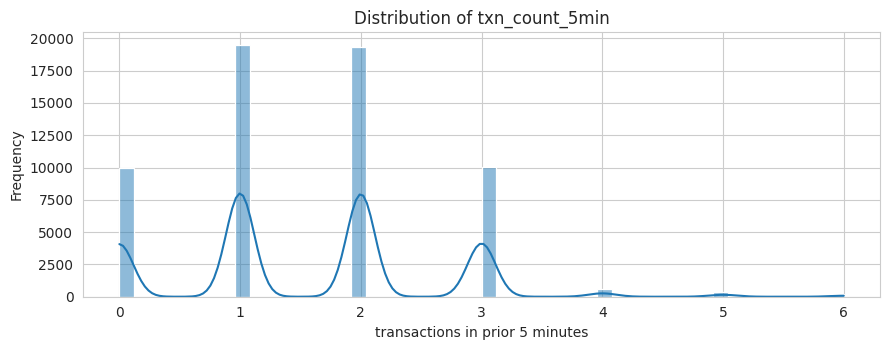

In [ ]:
histogram(data, 'txn_count_5min', title='Distribution of txn_count_5min', xlabel='transactions in prior 5 minutes')

**Observations**

* The vast majority of transactions are **isolated** (count of 1 in the prior 5 minutes).
* A small number show higher velocity (up to ~7) - rapid bursts that are strong candidates for automated fraud.

### `channel`

***Prompt***:

<font size=3 color="#4682B4"><b> Show the distribution of transactions across the different acceptance channels.
</font>

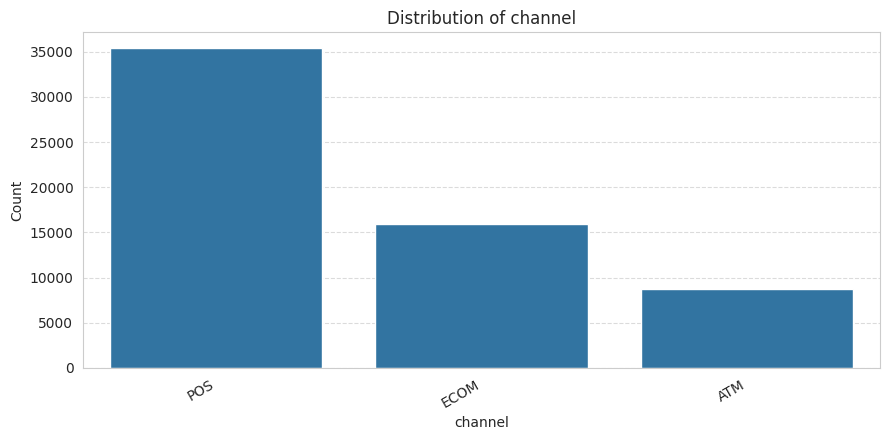

In [ ]:
barchart(data, 'channel', title='Distribution of channel', xlabel='channel')

**Observations**

* **POS (in-store) is the most common** channel, followed by ECOM (online) and then ATM.
* The channel mix matters because, as the bivariate analysis shows, fraud risk varies sharply across these channels.

### `txn_hour`

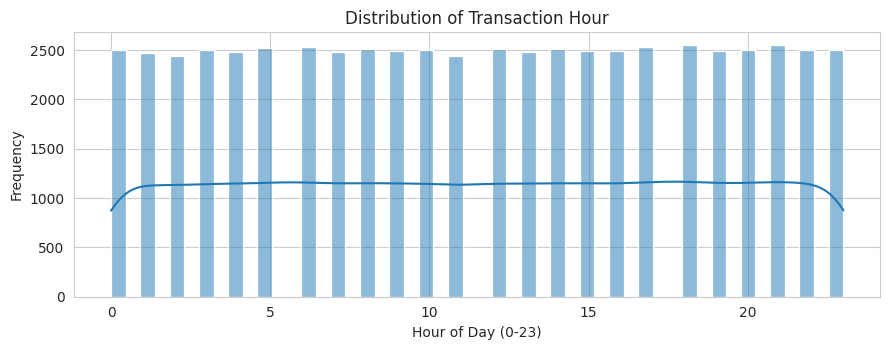

In [ ]:
histogram(data, 'txn_hour', title='Distribution of Transaction Hour', xlabel='Hour of Day (0-23)')

### `txn_day_of_week`

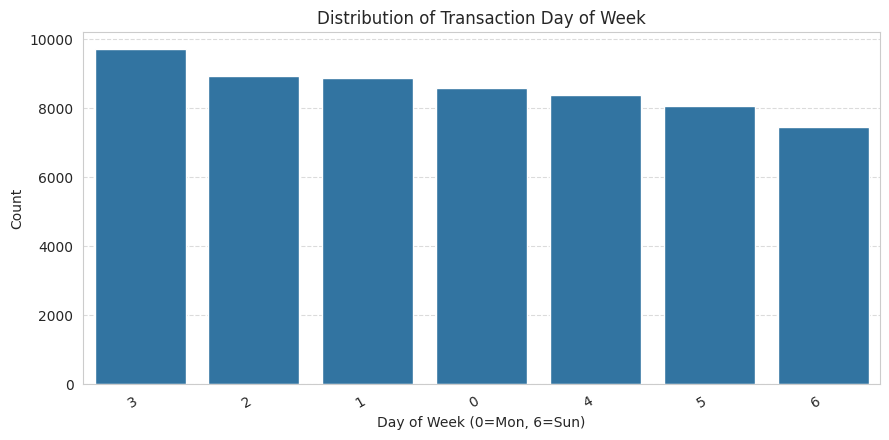

In [ ]:
barchart(data, 'txn_day_of_week', title='Distribution of Transaction Day of Week', xlabel='Day of Week (0=Mon, 6=Sun)')

### `avg_txn_amount_30d`

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the distribution of avg_txn_amount_30d.
</font>

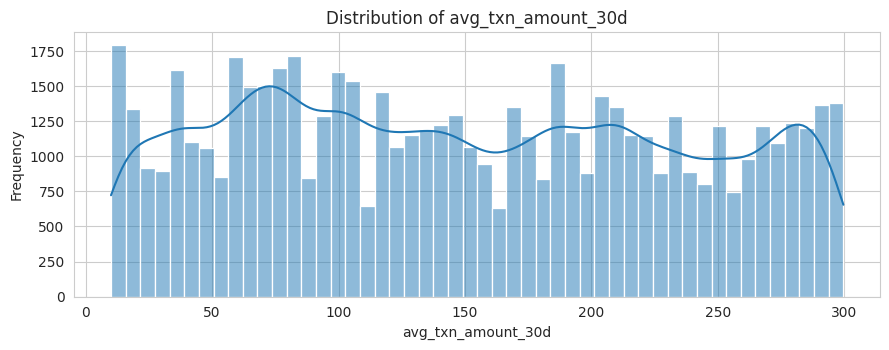

In [ ]:
histogram(data, 'avg_txn_amount_30d', title='Distribution of avg_txn_amount_30d', xlabel='avg_txn_amount_30d')

- The card's 30-day average spend clusters around ~145 with a moderate spread - it describes each card's baseline, against which the current amount can be judged.

### `max_txn_amount_90d`

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the distribution of max_txn_amount_90d.
</font>

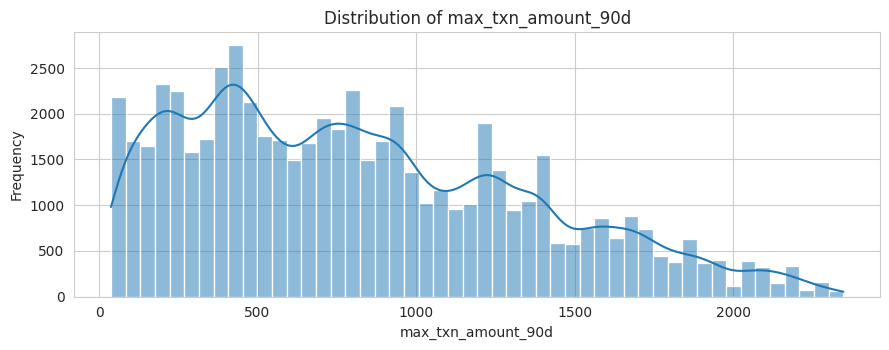

In [ ]:
histogram(data, 'max_txn_amount_90d', title='Distribution of max_txn_amount_90d', xlabel='max_txn_amount_90d')

- The largest charge on a card over 90 days is right-skewed with a long tail - a few cards have made very large purchases historically.

### `txn_count_1min`

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the distribution of txn_count_1min.
</font>

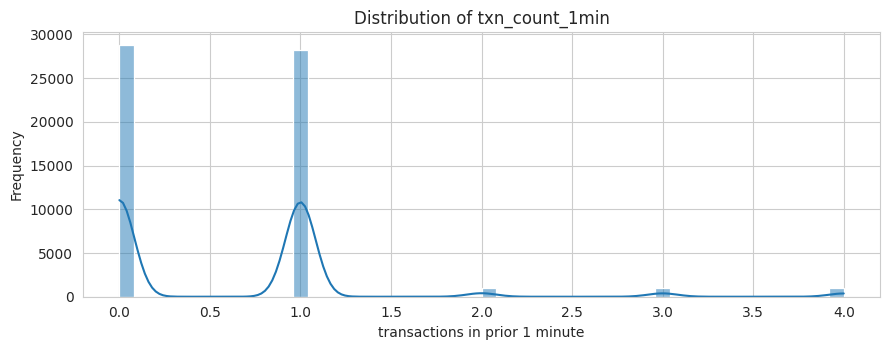

In [ ]:
histogram(data, 'txn_count_1min', title='Distribution of txn_count_1min', xlabel='transactions in prior 1 minute')

- Like the 5-minute count, the 1-minute velocity is almost always 1 (isolated transactions), with rare higher bursts.

### `cvv_fail_count_24h`

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the distribution of cvv_fail_count_24h.
</font>

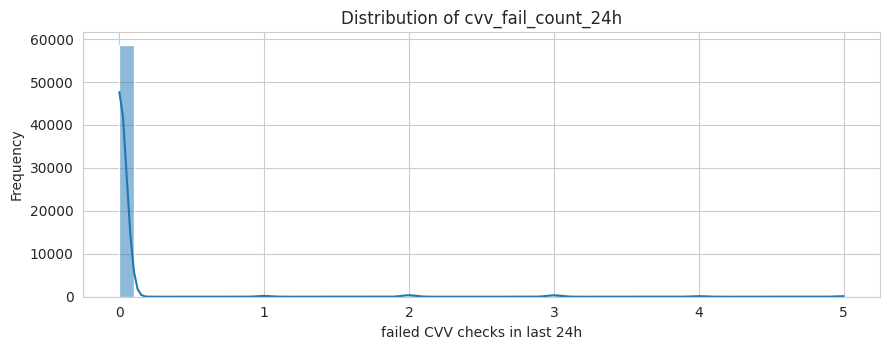

In [ ]:
histogram(data, 'cvv_fail_count_24h', title='Distribution of cvv_fail_count_24h', xlabel='failed CVV checks in last 24h')

- The overwhelming majority of transactions have zero recent CVV failures; a small tail shows repeated failures, which can indicate probing.

### `card_age_days` and `account_age_days`

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the distributions of card_age_days and account_age_days side by side.
</font>

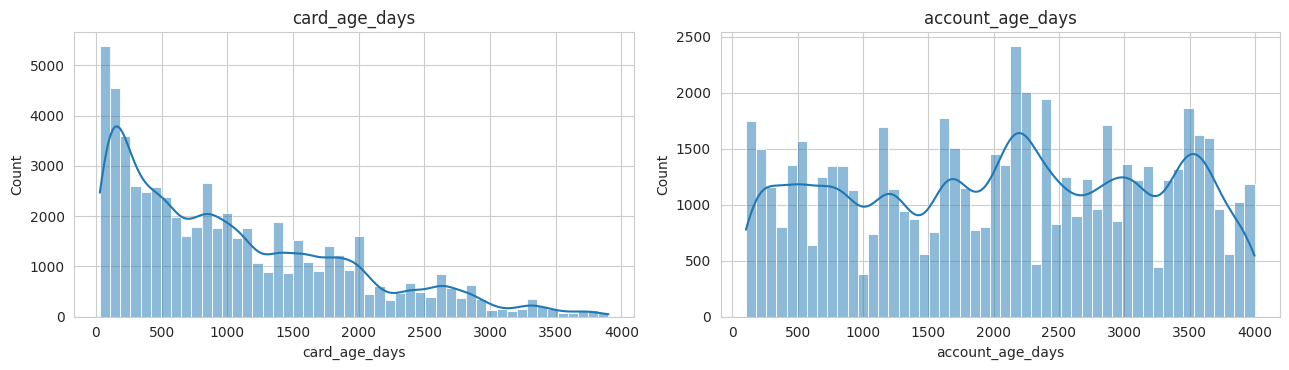

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(data['card_age_days'], bins=50, kde=True, ax=axes[0]); axes[0].set_title('card_age_days')
sns.histplot(data['account_age_days'], bins=50, kde=True, ax=axes[1]); axes[1].set_title('account_age_days')
plt.tight_layout(); plt.show()

- Both age features are broadly spread across the fleet of cards/accounts - slow-moving context rather than sharp signals.

### `entry_mode`, `cvv_result` (counts)

***Prompt***:

<font size=3 color="#4682B4"><b> Show the count distributions of entry_mode and cvv_result side by side.
</font>

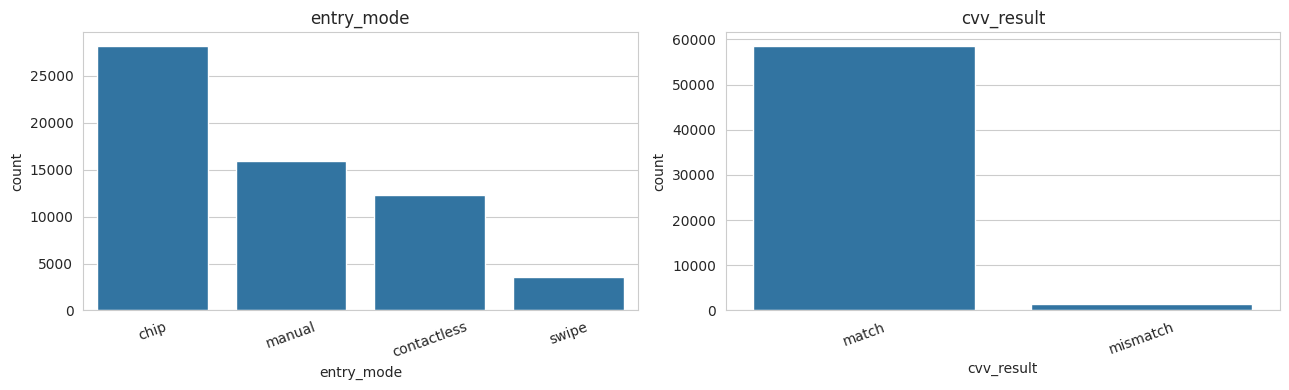

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=data, x='entry_mode', order=data['entry_mode'].value_counts().index, ax=axes[0]); axes[0].set_title('entry_mode')
sns.countplot(data=data, x='cvv_result', order=data['cvv_result'].value_counts().index, ax=axes[1]); axes[1].set_title('cvv_result')
for ax in axes: ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

- Chip is the most common entry mode; CVV mismatches are rare relative to matches - both consistent with a mostly-legitimate transaction base.

### `merchant_country`, `cardholder_country`, `merchant_category_code` (counts)

***Prompt***:

<font size=3 color="#4682B4"><b> Show the count distributions of merchant_country, cardholder_country, and merchant_category_code side by side.
</font>

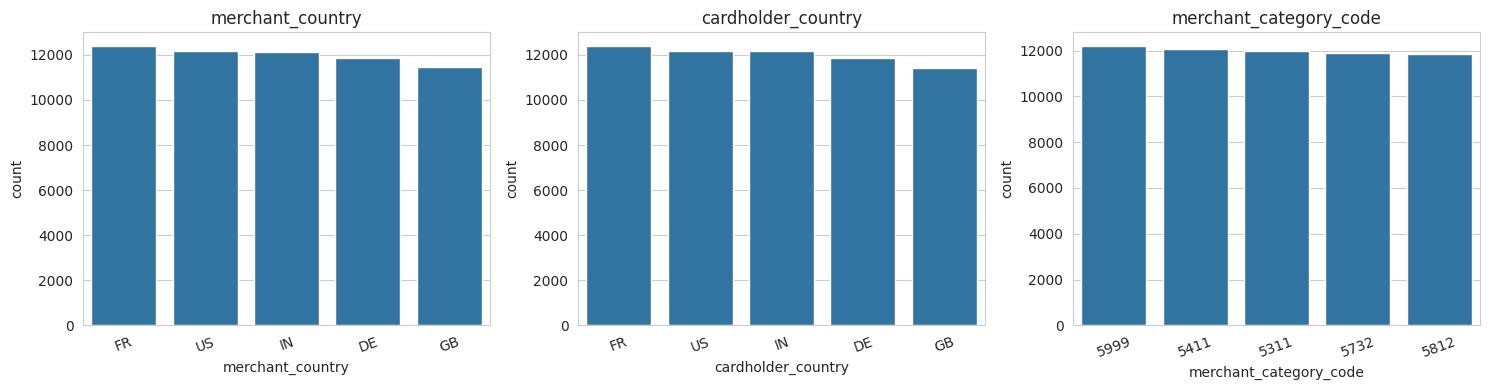

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['merchant_country', 'cardholder_country', 'merchant_category_code']):
    sns.countplot(data=data, x=col, order=data[col].value_counts().index, ax=ax); ax.set_title(col)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

- Countries and merchant categories are fairly evenly represented, so no single geography or category dominates the data.

### Binary flags overview (`cross_border_flag`, `is_new_device`, `is_new_merchant`, `device_country_mismatch`, `historical_fraud_flag`)

***Prompt***:

<font size=3 color="#4682B4"><b> Plot the prevalence (percentage present) of each binary risk flag.
</font>

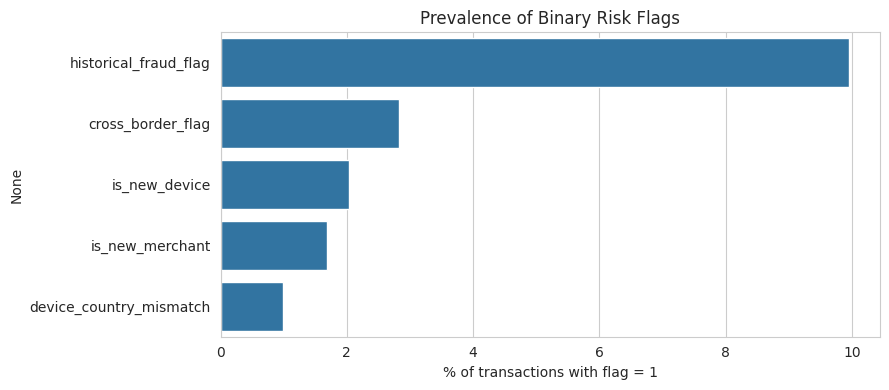

,0
historical_fraud_flag,9.95
cross_border_flag,2.82
is_new_device,2.04
is_new_merchant,1.69
device_country_mismatch,1.00


In [ ]:
flags = ['cross_border_flag','is_new_device','is_new_merchant','device_country_mismatch','historical_fraud_flag']
flag_share = (data[flags].mean()*100).sort_values(ascending=False)
plt.figure(figsize=(9,4))
sns.barplot(x=flag_share.values, y=flag_share.index)
plt.xlabel('% of transactions with flag = 1'); plt.title('Prevalence of Binary Risk Flags')
plt.tight_layout(); plt.show()
flag_share.round(2)

- All the risk flags are **rare events** (each present in only a small % of transactions) - which is why, despite their strong per-flag fraud rates, they fire on relatively few transactions.

### `txn_hour` and `txn_day_of_week` (engineered features)

***Prompt***:

<font size=3 color="#4682B4"><b> Show the count distributions of the engineered txn_hour and txn_day_of_week features.
</font>

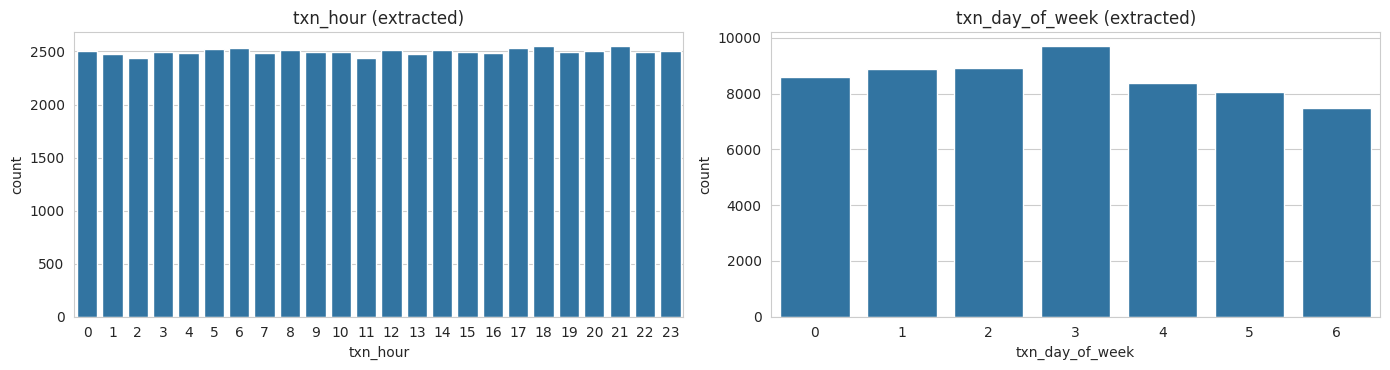

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
sns.countplot(data=data, x='txn_hour', ax=axes[0]); axes[0].set_title('txn_hour (extracted)')
sns.countplot(data=data, x='txn_day_of_week', ax=axes[1]); axes[1].set_title('txn_day_of_week (extracted)')
plt.tight_layout(); plt.show()

- The extracted time features spread transactions across hours and days. As noted in Feature Engineering, on this reconstructed timeline they do not carry strong fraud signal - confirmed next.

## Bivariate Analysis

### `is_fraud` vs `channel`

Do the acceptance channels differ in fraud risk? Online transactions lack a physical card check, so we expect ECOM to be riskier.

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate across the acceptance channels (POS, ECOM, ATM).
</font>

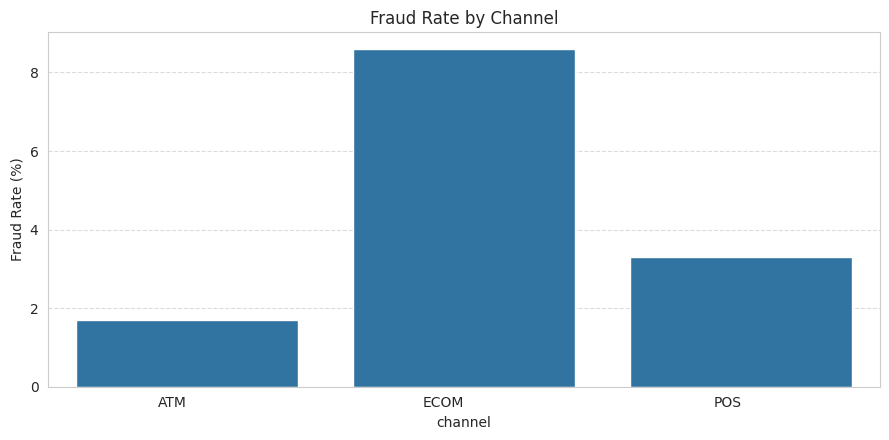

In [ ]:
barchart(fraud_rate_by(data, 'channel'), x_col='channel', y_col='fraud_rate_pct',
         title='Fraud Rate by Channel', xlabel='channel', ylabel='Fraud Rate (%)', rot=0)

**Observations**

* **ECOM (online) is the riskiest channel (~8.6%)**, ~ 2.6x the POS rate (~ 3.3%) and ~ 5x the ATM rate (~ 1.7%).
* Card-not-present online transactions lack the physical chip/PIN check, making them the natural fraud target.

### `is_fraud` vs `entry_mode`

Entry mode captures how the card was read. Chip and contactless carry cryptographic protection; manual and swipe do not.

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate across the different card entry modes.
</font>

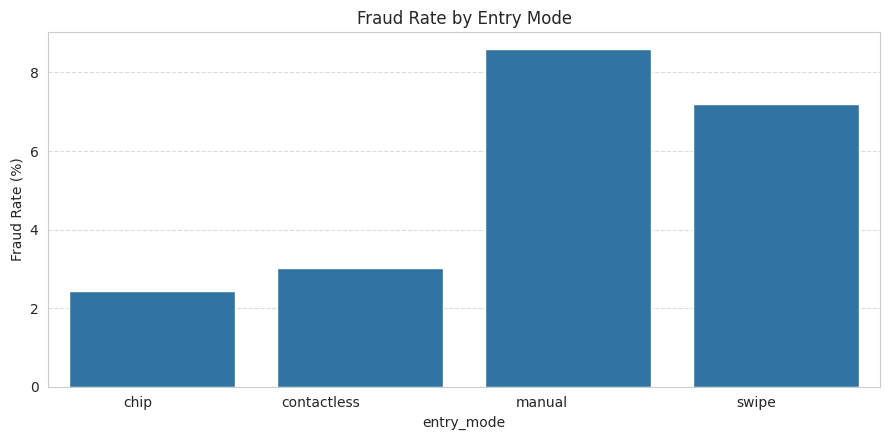

In [ ]:
barchart(fraud_rate_by(data, 'entry_mode'), x_col='entry_mode', y_col='fraud_rate_pct',
         title='Fraud Rate by Entry Mode', xlabel='entry_mode', ylabel='Fraud Rate (%)', rot=0)

**Observations**

* **Manual (~ 8.6%) and swipe (~ 7.2%) carry the highest fraud rates**; chip (~ 2.4%) and contactless (~ 3.0%) are much safer.
* The weaker, non-cryptographic entry modes are far more exploitable - a clear, actionable signal.

### `is_fraud` vs `transaction_amount`

Do fraudulent transactions differ in size from genuine ones? We compare the amount distributions across classes.

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the distribution of transaction_amount for genuine versus fraudulent transactions using a box plot.
</font>

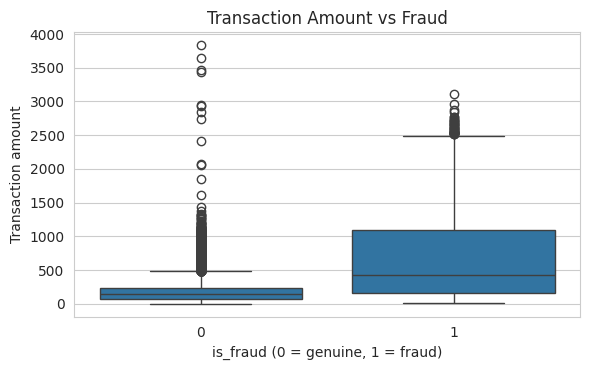

In [ ]:
boxplot(data, x_col='is_fraud', y_col='transaction_amount', title='Transaction Amount vs Fraud', xlabel='is_fraud (0 = genuine, 1 = fraud)', ylabel='Transaction amount')

**Observations**

* Fraudulent transactions carry a **higher median amount (~428 vs ~146, ~2.9x)** with a wider spread.
* Amount is useful but insufficient alone - many genuine transactions are also large, so it must be combined with context.

### `is_fraud` vs `device_country_mismatch`

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate by the device-country-mismatch flag.
</font>

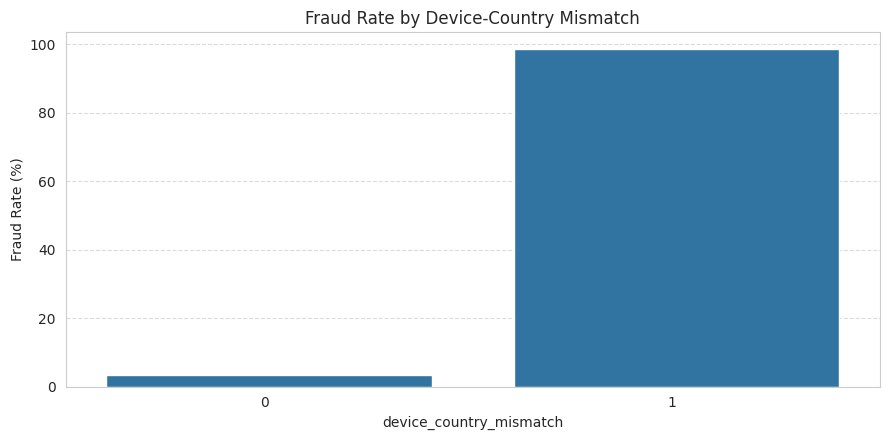

In [ ]:
barchart(fraud_rate_by(data, 'device_country_mismatch'), x_col='device_country_mismatch', y_col='fraud_rate_pct', title='Fraud Rate by Device-Country Mismatch', xlabel='device_country_mismatch', ylabel='Fraud Rate (%)', rot=0)

- A device-country mismatch pushes the fraud rate to ~98% - another near-decisive but rare flag, in the same family as new-device and new-merchant.

### `is_fraud` vs `merchant_fraud_rate_30d`

***Prompt***:

<font size=3 color="#4682B4"><b> Compare merchant_fraud_rate_30d for genuine versus fraudulent transactions.
</font>

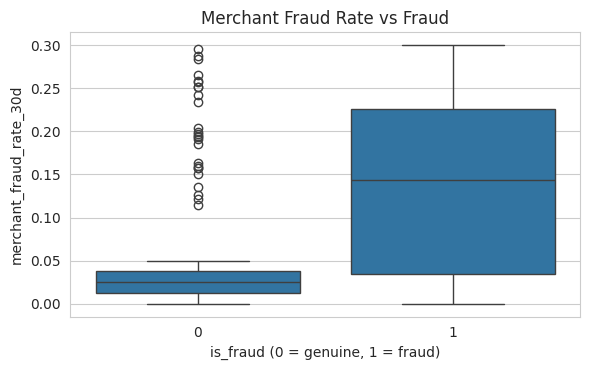

In [ ]:
boxplot(data, x_col='is_fraud', y_col='merchant_fraud_rate_30d', title='Merchant Fraud Rate vs Fraud', xlabel='is_fraud (0 = genuine, 1 = fraud)', ylabel='merchant_fraud_rate_30d')

- Fraudulent transactions occur at merchants with clearly higher recent fraud rates (median ~0.14 vs ~0.03) - one of the strongest continuous separators.

### `is_fraud` vs `txn_count_1min` and `txn_count_5min`

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate across the 1-minute and 5-minute velocity counts side by side.
</font>

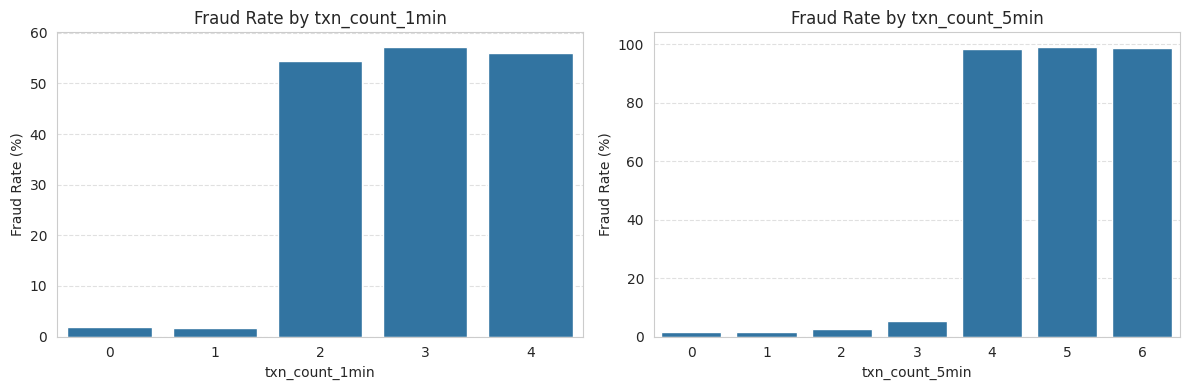

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['txn_count_1min','txn_count_5min']):
    tmp = fraud_rate_by(data, col); sns.barplot(data=tmp, x=col, y='fraud_rate_pct', ax=ax)
    ax.set_title(f'Fraud Rate by {col}'); ax.set_ylabel('Fraud Rate (%)'); ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout(); plt.show()

- Fraud rate **rises steeply with velocity**: the more transactions in the prior 1 or 5 minutes, the higher the fraud rate - the burst pattern of automated attacks.

### `is_fraud` vs `distance_from_last_txn_km`

***Prompt***:

<font size=3 color="#4682B4"><b> Compare distance_from_last_txn_km for genuine versus fraudulent transactions.
</font>

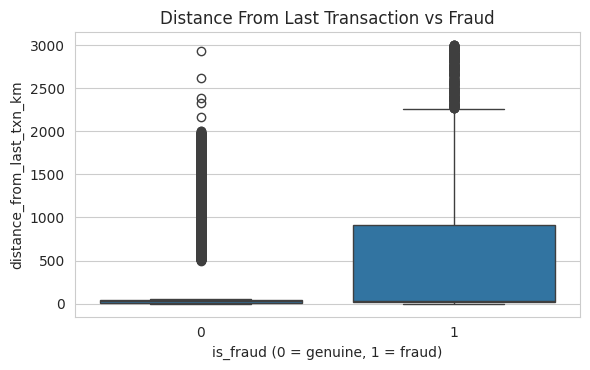

In [ ]:
boxplot(data, x_col='is_fraud', y_col='distance_from_last_txn_km', title='Distance From Last Transaction vs Fraud', xlabel='is_fraud (0 = genuine, 1 = fraud)', ylabel='distance_from_last_txn_km')

- Fraudulent transactions sit at modestly higher distances (median ~32 vs ~25 km), with a heavier tail - geographic jumps contribute signal, though less sharply than the flags.

### `is_fraud` vs `cvv_fail_count_24h`

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate by the number of failed CVV checks in the last 24 hours.
</font>

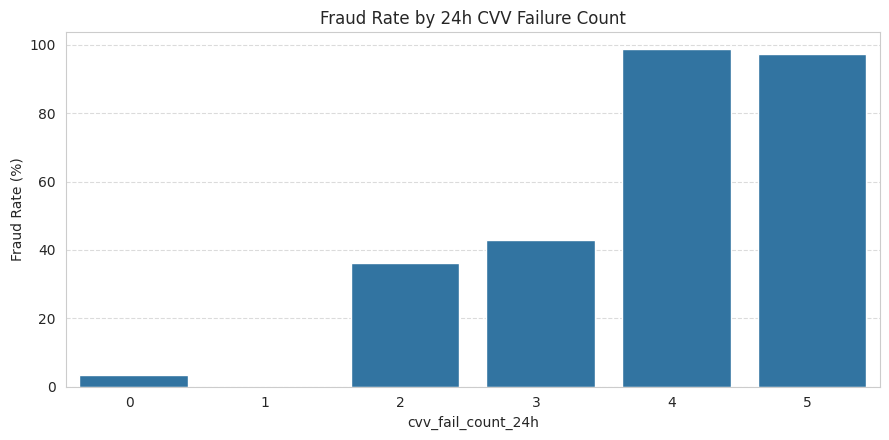

In [ ]:
barchart(fraud_rate_by(data, 'cvv_fail_count_24h'), x_col='cvv_fail_count_24h', y_col='fraud_rate_pct', title='Fraud Rate by 24h CVV Failure Count', xlabel='cvv_fail_count_24h', ylabel='Fraud Rate (%)', rot=0)

- Fraud rate increases with the number of recent CVV failures - repeated failed checks are a probing signature.

### `is_fraud` vs `merchant_category_code`

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate across merchant categories.
</font>

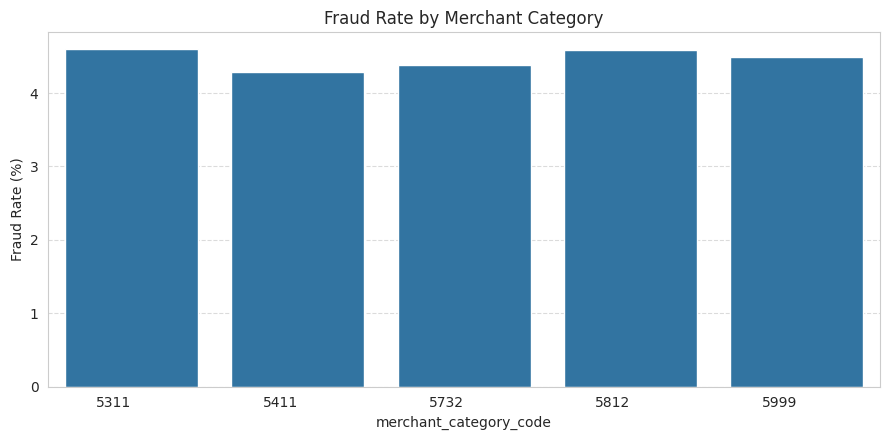

In [ ]:
barchart(fraud_rate_by(data, 'merchant_category_code'), x_col='merchant_category_code', y_col='fraud_rate_pct', title='Fraud Rate by Merchant Category', xlabel='merchant_category_code', ylabel='Fraud Rate (%)', rot=0)

- Fraud rate is fairly **flat across merchant categories** (~4.3-4.6%), so category on its own is a weak predictor here.

### `is_fraud` vs `merchant_country` and `cardholder_country`

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate across merchant_country and cardholder_country side by side.
</font>

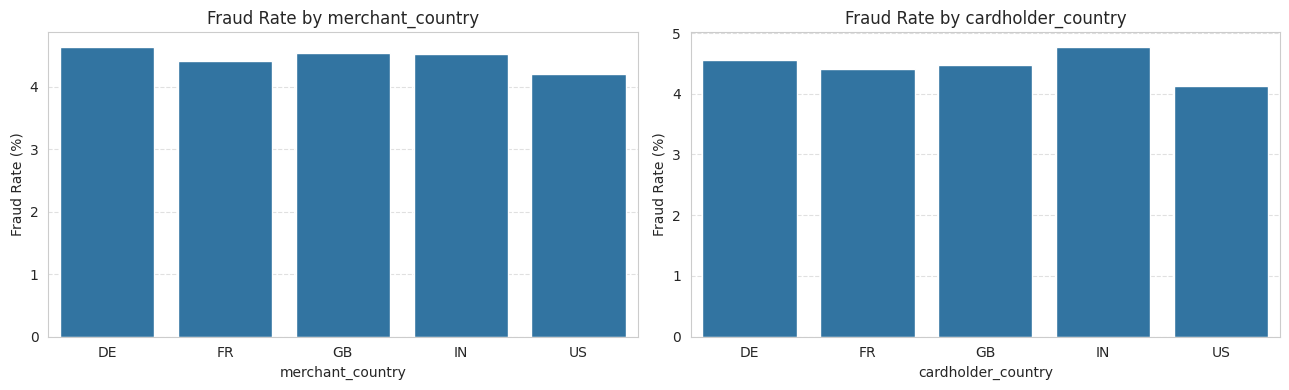

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ['merchant_country','cardholder_country']):
    tmp = fraud_rate_by(data, col); sns.barplot(data=tmp, x=col, y='fraud_rate_pct', ax=ax)
    ax.set_title(f'Fraud Rate by {col}'); ax.set_ylabel('Fraud Rate (%)'); ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout(); plt.show()

- Fraud rate barely varies by individual country (~3.8-4.9%); it is the **mismatch** between merchant and cardholder country (`cross_border_flag`), not the country itself, that carries the signal.

### `is_fraud` vs `historical_fraud_flag`

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate by the historical fraud flag.
</font>

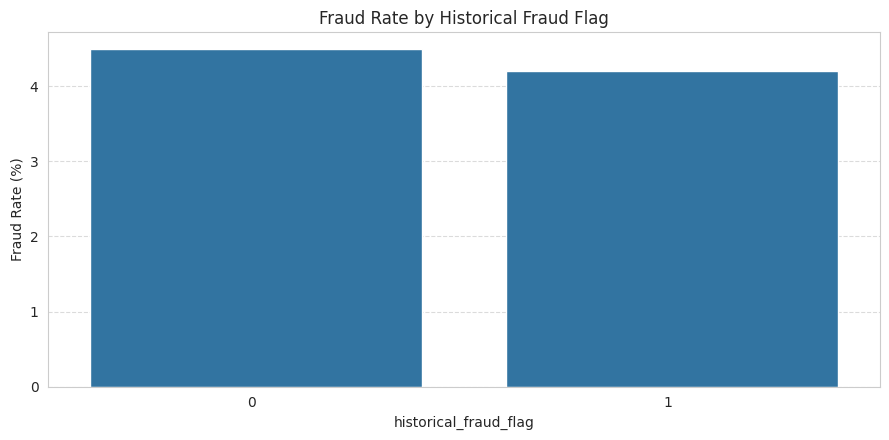

In [ ]:
barchart(fraud_rate_by(data, 'historical_fraud_flag'), x_col='historical_fraud_flag', y_col='fraud_rate_pct', title='Fraud Rate by Historical Fraud Flag', xlabel='historical_fraud_flag', ylabel='Fraud Rate (%)', rot=0)

- Cards with a prior fraud event show a marginally different rate; the effect is weak in this data, so it is legitimate but low-value context.

### `is_fraud` vs `txn_hour` and `txn_day_of_week` (engineered)

***Prompt***:

<font size=3 color="#4682B4"><b> Compare the fraud rate across the engineered txn_hour and txn_day_of_week features.
</font>

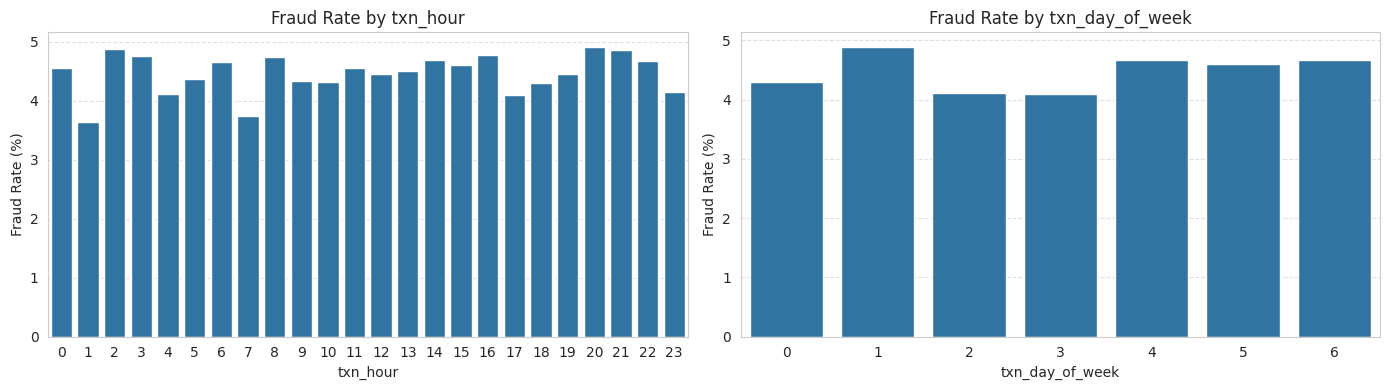

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['txn_hour','txn_day_of_week']):
    tmp = fraud_rate_by(data, col); sns.barplot(data=tmp, x=col, y='fraud_rate_pct', ax=ax)
    ax.set_title(f'Fraud Rate by {col}'); ax.set_ylabel('Fraud Rate (%)'); ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout(); plt.show()

- As anticipated in Feature Engineering, fraud rate is **essentially flat across hours (~3.6-4.9%) and days of week (~4.1-4.9%)** on this reconstructed timeline. The extracted time features carry little signal here - a useful, honest reminder that a correctly-applied technique does not guarantee a predictive feature, and that its value depends on the underlying data.

### `is_fraud` vs `avg_txn_amount_30d` and `max_txn_amount_90d`

***Prompt***:

<font size=3 color="#4682B4"><b> Compare avg_txn_amount_30d and max_txn_amount_90d for genuine versus fraudulent transactions.
</font>

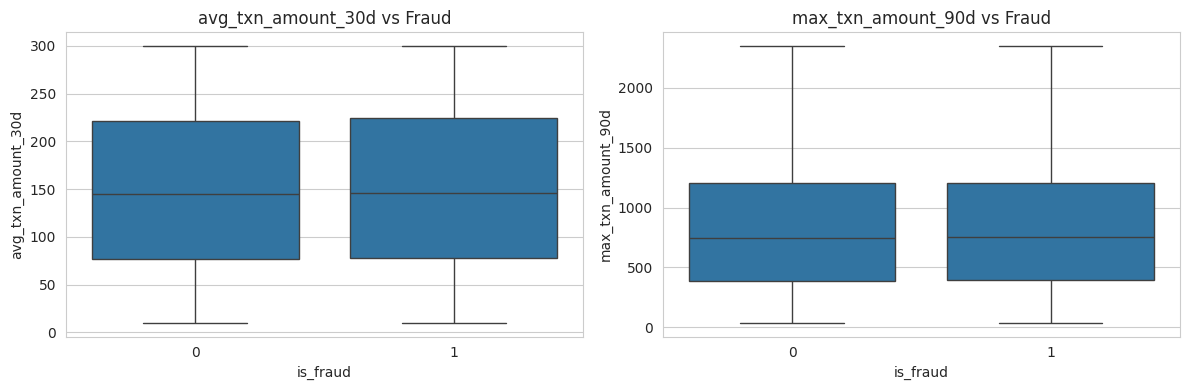

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['avg_txn_amount_30d','max_txn_amount_90d']):
    sns.boxplot(data=data, x='is_fraud', y=col, ax=ax)
    ax.set_title(f'{col} vs Fraud'); ax.set_xlabel('is_fraud')
plt.tight_layout(); plt.show()

- The card's own baseline spend (`avg_txn_amount_30d`) and 90-day max are **similar for fraud and genuine** - fraud is better detected by the *current* amount relative to context than by these baselines alone.

### `is_fraud` vs `card_age_days` and `account_age_days`

***Prompt***:

<font size=3 color="#4682B4"><b> Compare card_age_days and account_age_days for genuine versus fraudulent transactions.
</font>

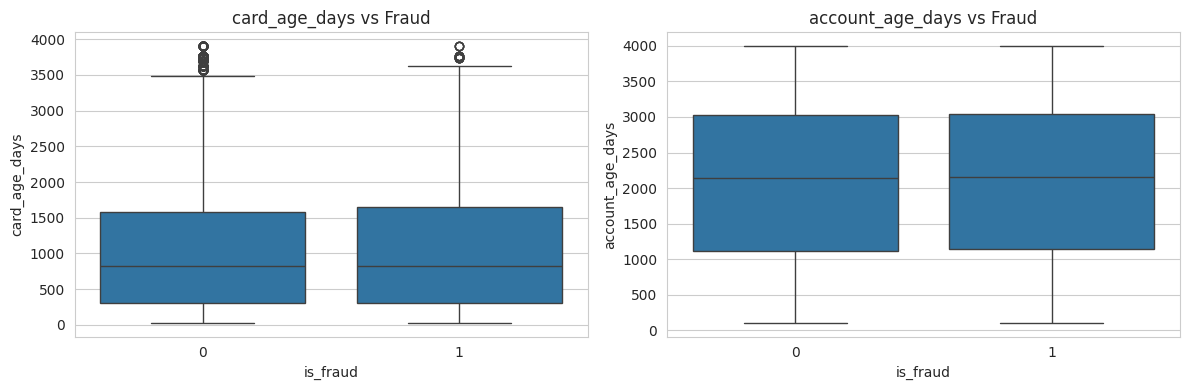

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['card_age_days','account_age_days']):
    sns.boxplot(data=data, x='is_fraud', y=col, ax=ax)
    ax.set_title(f'{col} vs Fraud'); ax.set_xlabel('is_fraud')
plt.tight_layout(); plt.show()

- Card and account age distributions are nearly identical across fraud and genuine transactions - age is not a meaningful predictor in this dataset.

<font size=5 color='#4682B4'><b>End of Notebook</b></font>

___